# 🔥 PyTorch (y el resto de librerías) para Redes Neuronales
### De tus apuntes en NumPy a los frameworks profesionales

**Objetivo:** aprender a usar **PyTorch al completo** —tensores, autograd, `nn`, pérdidas, optimizadores, datos, regularización, CNN, secuencias, guardado y GPU— y conocer el resto del ecosistema (scikit-learn, Keras/TensorFlow, JAX, Lightning, Hugging Face).

**Prerrequisito:** el cuaderno anterior *«Redes Neuronales desde Cero con NumPy»*. Aquí **no repetimos la teoría: la reutilizamos.** Cada vez que PyTorch automatiza algo que antes hiciste a mano, lo **verificamos numéricamente contra tus propios resultados** (la red $2\to2\to1$ del Bloque 3, los gradientes de §5.4, el XOR del Bloque 6…). Así verás que PyTorch no es magia: es *tu mismo código, automatizado*.

**Metodología** (la misma que antes):

> intuición → ecuación → ejemplo numérico → código

## Índice

| Bloque | Tema | Lo que ya sabes y vamos a automatizar |
|---|---|---|
| 0 | Puente: de NumPy a PyTorch | tus convenciones y dimensiones |
| 1 | Tensores | `np.array` y broadcasting |
| 2 | Autograd | `backward()` y la regla de la cadena (§5.3) |
| 3 | `torch.nn`: capas y modelos | `W @ A + b`, tu clase `NeuralNetwork` |
| 4 | Funciones de pérdida | $\mathcal L$, $J$, MSE, entropía cruzada (Bloque 4) |
| 5 | Optimizadores y *schedulers* | $W:=W-\alpha\,dW$ (§5.1), momentum, Adam |
| 6 | El bucle de entrenamiento: XOR | tu `fit()` (Bloque 6) |
| 7 | Datos: `Dataset` y `DataLoader` | mini-lotes |
| 8 | Clasificación multiclase y evaluación | softmax y entropía cruzada categórica |
| 9 | Regularización y trucos de entrenamiento | $L_2$, *dropout*, BatchNorm, *early stopping* |
| 10 | Guardar, reproducir y GPU | — |
| 11 | Arquitecturas: CNN, secuencias, atención | — |
| 12 | Otras librerías: scikit-learn, Keras/TF, JAX, Lightning, Hugging Face | — |
| 13 | Errores típicos, chuleta y ejercicios | — |

## El ciclo de aprendizaje, ahora con PyTorch

```mermaid
flowchart LR
    D[DataLoader: lote X,y] --> F[Forward: modelo nn.Module]
    F --> L[Pérdida: criterion]
    L --> Z[optimizer.zero_grad]
    Z --> B[loss.backward: autograd]
    B --> U[optimizer.step]
    U --> D
```

*(Si tu visor no renderiza Mermaid, es el mismo ciclo de siempre: **predecir → medir error → calcular gradientes → corregir pesos → repetir**.)*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

np.set_printoptions(precision=5, suppress=True)       # salida NumPy legible (como en tus apuntes)
torch.set_printoptions(precision=5, sci_mode=False)   # ...y salida de tensores también
plt.rcParams["figure.figsize"] = (7, 4)

print("NumPy  ", np.__version__)
print("PyTorch", torch.__version__)
print("¿GPU CUDA disponible?", torch.cuda.is_available())

NumPy   2.5.2
PyTorch 2.14.1+cu132
¿GPU CUDA disponible? True


---
# Bloque 0 · Puente: de tus apuntes a PyTorch

## 0.1 ¿Qué es PyTorch y qué hace por ti?

PyTorch es una librería de **tensores** (arrays $n$-dimensionales como los de NumPy) con tres superpoderes:

1. **Autograd:** calcula *automáticamente* los gradientes (tu retropropagación del Bloque 5, sin derivar a mano).
2. **GPU/aceleradores:** el mismo código corre en CPU o en GPU cambiando una línea.
3. **`torch.nn` / `torch.optim`:** capas, pérdidas y optimizadores ya escritos y probados.

> **Idea central:** PyTorch **no cambia las matemáticas** que ya conoces; automatiza la *contabilidad*. Todo lo que escribiste en el cuaderno anterior tiene un equivalente directo:

| Lo que hiciste a mano | Dónde estaba | En PyTorch |
|---|---|---|
| Arrays | `np.array` (Bloque 1) | `torch.Tensor` (Bloque 1 de este cuaderno) |
| Forward $Z=WA+b$, $A=g(Z)$ | Bloques 2-3 | `nn.Linear`, `nn.Sequential`, `nn.Module` (Bloque 3) |
| Pérdida / coste $\mathcal L$, $J$ | Bloque 4 | `nn.MSELoss`, `nn.BCEWithLogitsLoss`, `nn.CrossEntropyLoss` (Bloque 4) |
| `backward()`: regla de la cadena | §5.3 | `loss.backward()` (autograd, Bloque 2) |
| `update()`: $W:=W-\alpha\,dW$ | §5.1 | `torch.optim.SGD`, `Adam`… (Bloque 5) |
| `fit()`: el bucle | Bloque 6 | el bucle de entrenamiento (Bloque 6) |
| `gradient_check` | §5.4 / Bloque 6 | `torch.autograd.gradcheck` (Bloque 2) |
| Inicialización Xavier/He | §6.1 | `nn.init.xavier_*`, `kaiming_*` (Bloque 3) |

## 0.2 Instalación

```bash
pip install torch          # CPU, o GPU NVIDIA si tu sistema la soporta
# Para elegir la versión exacta (CUDA, ROCm, solo CPU): https://pytorch.org/get-started/locally/
pip install torchvision    # opcional: visión (datasets, modelos preentrenados)
```

Comprueba la instalación con la celda de arriba: debe imprimir la versión y si hay GPU disponible. **Todo este cuaderno funciona en CPU.**

## 0.3 Dos diferencias con tus apuntes que debes tener grabadas

### (1) Los ejemplos van en **filas**, no en columnas

En tus apuntes $A^{[l-1]}\in\mathbb R^{n^{[l-1]}\times m}$ (ejemplos en **columnas**) y $Z=WA+b$. PyTorch, como pandas y scikit-learn, pone los ejemplos en **filas**: $X\in\mathbb R^{m\times n^{[l-1]}}$. Trasponiendo la ecuación de tus apuntes:

$$Z^{T}=\bigl(WA+b\bigr)^{T}=A^{T}W^{T}+b^{T}\quad\Longrightarrow\quad\boxed{Z_{\text{torch}}=X\,W^{T}+b}\qquad\text{con }X=A^{T}$$

Lo importante: **la matriz $W$ es *la misma* y tiene la misma forma** $(n^{[l]},n^{[l-1]})$. Solo se traspone el lote de datos. El sesgo $b$ pasa de $(n^{[l]},1)$ a $(n^{[l]},)$ y sigue "sumándose a cada ejemplo" por *broadcasting*.

| Concepto | Tus apuntes (NumPy) | PyTorch |
|---|---|---|
| Lote de datos | $X$: $(n^{[0]},\,m)$ | $X$: $(m,\,n^{[0]})$ |
| Pesos $W^{[l]}$ | $(n^{[l]},\,n^{[l-1]})$ | `capa.weight`: $(n^{[l]},\,n^{[l-1]})$ — **igual** |
| Sesgo $b^{[l]}$ | $(n^{[l]},\,1)$ | `capa.bias`: $(n^{[l]},)$ |
| Forward | $Z=WA+b$ | $Z=XW^{T}+b$ (lo hace `nn.Linear`) |
| Etiquetas | $Y$: $(1,\,m)$ | $(m,1)$ o $(m,)$ según la pérdida |
| Gradiente $dW$ | $(n^{[l]},\,n^{[l-1]})$ | `capa.weight.grad`: igual que `weight` |

### (2) `float32` frente a `float64`

NumPy usa `float64` por defecto; PyTorch usa **`float32`** (más rápido y ocupa la mitad; sobra para entrenar redes). Mezclarlos da errores (lo veremos en §1.3).

### Comprobación: `nn.Linear` es tu `W @ A + b` con los datos traspuestos

In [2]:
rng = np.random.default_rng(1)
n0, n1, m = 3, 4, 5
W = rng.normal(size=(n1, n0)); b = rng.normal(size=(n1, 1)); A_prev = rng.normal(size=(n0, m))

# Tus apuntes: ejemplos en COLUMNAS
Z_apuntes = W @ A_prev + b                                  # (4,3)@(3,5) + (4,1) -> (4,5)

# PyTorch: una capa lineal 3 -> 4, con EXACTAMENTE los mismos pesos
capa = nn.Linear(n0, n1)
with torch.no_grad():
    capa.weight.copy_(torch.from_numpy(W))                  # (4,3): ¡misma forma que W!
    capa.bias.copy_(torch.from_numpy(b.ravel()))            # (4,)
X = torch.tensor(A_prev.T, dtype=torch.float32)             # (5,3): ejemplos en FILAS
Z_torch = capa(X)                                           # (5,4)

print("W de tus apuntes     :", W.shape, "| capa.weight:", tuple(capa.weight.shape))
print("Z de tus apuntes     :", Z_apuntes.shape, "| Z de PyTorch  :", tuple(Z_torch.shape), "  (traspuestos)")
print("¿Z_torch == Z_apuntes.T?", np.allclose(Z_apuntes.T, Z_torch.detach().numpy(), atol=1e-6))

W de tus apuntes     : (4, 3) | capa.weight: (4, 3)
Z de tus apuntes     : (4, 5) | Z de PyTorch  : (5, 4)   (traspuestos)
¿Z_torch == Z_apuntes.T? True


---
# Bloque 1 · Tensores

## 1.1 Qué es un tensor

Un **tensor** es un array $n$-dimensional con tres atributos clave: su **forma** (`shape`), su **tipo de dato** (`dtype`) y el **dispositivo** donde vive (`device`: CPU o GPU). Además puede llevar la historia necesaria para derivar (Bloque 2).

| Rango (`ndim`) | Nombre | Ejemplo en redes neuronales | `shape` típica |
|:-:|---|---|---|
| 0 | escalar | la pérdida $\mathcal L$ o $J$ | `()` |
| 1 | vector | un ejemplo $x$, un sesgo $b$ | `(3,)` |
| 2 | matriz | un lote de datos, unos pesos $W$ | `(32, 3)` |
| 3 | — | un lote de secuencias: (lote, tiempo, características) | `(32, 10, 8)` |
| 4 | — | un lote de imágenes: (lote, canales, alto, ancho) | `(32, 1, 28, 28)` |

## 1.2 Crear tensores

Casi todas las funciones tienen su gemela en NumPy:

| NumPy | PyTorch | Nota |
|---|---|---|
| `np.array([..])` | `torch.tensor([..])` | copia los datos |
| `np.zeros`, `np.ones`, `np.full` | `torch.zeros`, `torch.ones`, `torch.full` | |
| `np.arange`, `np.linspace`, `np.eye` | `torch.arange`, `torch.linspace`, `torch.eye` | |
| `rng.random`, `rng.normal` | `torch.rand`, `torch.randn` | uniforme y normal estándar |
| `np.zeros_like(a)` | `torch.zeros_like(a)` | misma forma y dtype |

In [3]:
a = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.]])                      # desde una lista de listas
print(a)
print("forma:", a.shape, "| dtype:", a.dtype, "| device:", a.device, "| ndim:", a.ndim, "| nº elementos:", a.numel())

print("\nzeros:\n", torch.zeros(2, 3))
print("full:\n", torch.full((2, 2), 7.0))
print("eye:\n", torch.eye(3))
print("arange(0,10,2):", torch.arange(0, 10, 2))
print("linspace(0,1,5):", torch.linspace(0, 1, 5))
print("zeros_like(a):\n", torch.zeros_like(a))

torch.manual_seed(0)                                  # reproducibilidad (como default_rng(seed))
print("\nrand (uniforme):\n", torch.rand(2, 3))
print("randn (normal estándar):\n", torch.randn(2, 3))
print("randint:\n", torch.randint(0, 10, (2, 3)))

tensor([[1., 2., 3.],
        [4., 5., 6.]])
forma: torch.Size([2, 3]) | dtype: torch.float32 | device: cpu | ndim: 2 | nº elementos: 6

zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
full:
 tensor([[7., 7.],
        [7., 7.]])
eye:
 tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])
arange(0,10,2): tensor([0, 2, 4, 6, 8])
linspace(0,1,5): tensor([0.00000, 0.25000, 0.50000, 0.75000, 1.00000])
zeros_like(a):
 tensor([[0., 0., 0.],
        [0., 0., 0.]])

rand (uniforme):
 tensor([[0.49626, 0.76822, 0.08848],
        [0.13203, 0.30742, 0.63408]])
randn (normal estándar):
 tensor([[ 1.26446, -0.68743,  0.16038],
        [-0.60645, -0.78306,  1.06217]])
randint:
 tensor([[4, 3, 6],
        [9, 1, 4]])


## 1.3 Tipos de datos (`dtype`)

| `dtype` | Alias | Para qué se usa |
|---|---|---|
| `torch.float32` | `float` | **por defecto**: datos y parámetros de las redes |
| `torch.float64` | `double` | comparar con NumPy, `gradcheck` |
| `torch.float16`, `torch.bfloat16` | `half` | precisión mixta en GPU (Bloque 10) |
| `torch.int64` | `long` | **etiquetas de clase** (`CrossEntropyLoss`), índices |
| `torch.bool` | — | máscaras |

⚠️ **Dos trampas clásicas:** (1) `torch.tensor([1., 2.])` es `float32`, mientras que NumPy da `float64`; (2) las etiquetas de clase deben ser **`long`**, no `float`.

In [4]:
x = torch.tensor([1, 2, 3]);      print("enteros   ->", x.dtype)                 # int64
y = torch.tensor([1., 2., 3.]);   print("decimales ->", y.dtype)                 # float32  (¡no float64!)
print("NumPy     ->", np.array([1., 2., 3.]).dtype)                              # float64

# Conversiones: .to(dtype)  /  .float()  .double()  .long()
print("convertido:", y.to(torch.float64).dtype, y.double().dtype, y.long().dtype)

# Mezclar float32 con float64 en una capa: error típico
try:
    nn.Linear(3, 2)(torch.tensor([[1., 2., 3.]], dtype=torch.float64))
except RuntimeError as e:
    print("\nError típico (float64 con parámetros float32):\n  ", e)

enteros   -> torch.int64
decimales -> torch.float32
NumPy     -> float64
convertido: torch.float64 torch.float64 torch.int64

Error típico (float64 con parámetros float32):
   mat1 and mat2 must have the same dtype, but got Double and Float


## 1.4 Operaciones básicas

| Operación | NumPy | PyTorch |
|---|---|---|
| Elemento a elemento ($\odot$) | `A * B` | `A * B` |
| Producto matricial | `A @ B` | `A @ B` (o `torch.matmul`) |
| Traspuesta | `A.T` | `A.T` |
| Suma/media por eje | `A.sum(axis=0, keepdims=True)` | `A.sum(dim=0, keepdim=True)` |
| Máximo por eje | `A.max(axis=1)` | `A.max(dim=1)` → **devuelve (valores, índices)** |
| Posición del máximo | `A.argmax(axis=1)` | `A.argmax(dim=1)` |
| Tensor de 1 elemento → número | `float(a)` | `a.item()` |

Observa el cambio de nombre: `axis` → **`dim`** y `keepdims` → **`keepdim`**.

In [5]:
A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[0., 1.], [1., 0.]])
print("A * B  (elemento a elemento, ⊙):\n", A * B)
print("A @ B  (producto matricial):\n", A @ B)
print("A.T:\n", A.T)

# Reducciones: dim == axis,  keepdim == keepdims
print("\nsuma total              :", A.sum().item())
print("suma por columnas (dim=0):", A.sum(dim=0))
print("suma por filas, keepdim :\n", A.sum(dim=1, keepdim=True))
print("media                   :", A.mean().item())
valores, indices = A.max(dim=1)                       # con dim devuelve DOS cosas
print("max por fila:", valores, "en las posiciones", indices, "| argmax:", A.argmax(dim=1))

# Las activaciones del Bloque 1 de tus apuntes
z = torch.linspace(-2, 2, 5)
print("\nz       :", z)
print("sigmoid :", torch.sigmoid(z))
print("tanh    :", torch.tanh(z))
print("relu    :", torch.relu(z))

A * B  (elemento a elemento, ⊙):
 tensor([[0., 2.],
        [3., 0.]])
A @ B  (producto matricial):
 tensor([[2., 1.],
        [4., 3.]])
A.T:
 tensor([[1., 3.],
        [2., 4.]])

suma total              : 10.0
suma por columnas (dim=0): tensor([4., 6.])
suma por filas, keepdim :
 tensor([[3.],
        [7.]])
media                   : 2.5
max por fila: tensor([2., 4.]) en las posiciones tensor([1, 1]) | argmax: tensor([1, 1])

z       : tensor([-2., -1.,  0.,  1.,  2.])
sigmoid : tensor([0.11920, 0.26894, 0.50000, 0.73106, 0.88080])
tanh    : tensor([-0.96403, -0.76159,  0.00000,  0.76159,  0.96403])
relu    : tensor([0., 0., 0., 1., 2.])


## 1.5 Broadcasting

Mismas reglas que NumPy: se alinean las formas **por la derecha** y cada par de dimensiones debe ser **igual o 1**. Es lo que hace que sumar el sesgo $b$ a todos los ejemplos funcione:

```
 Z   (m, n1)  =  X Wᵀ (m, n1)  +  b (n1,)        ← b se "estira" a lo largo de las m filas
```

⚠️ **El bug silencioso más común en PyTorch:** si las formas no son las que crees, el broadcasting *no da error*, sino un resultado equivocado.

In [6]:
Z = torch.zeros(5, 4)                                  # (m=5 ejemplos, n1=4 neuronas)
b = torch.tensor([1., 2., 3., 4.])                     # (4,)
print("(5,4) + (4,)  ->", (Z + b).shape, "  ✓ b se suma a cada fila")

# El bug silencioso: restar (3,) y (3,1)
y_hat = torch.tensor([0.9, 0.2, 0.6])                  # (3,)
y     = torch.tensor([[1.], [0.], [0.]])               # (3,1)
print("(3,) - (3,1) ->", (y_hat - y).shape, "  ✗ ¡no es (3,)! Se ha formado una matriz 3×3 sin avisar")

(5,4) + (4,)  -> torch.Size([5, 4])   ✓ b se suma a cada fila
(3,) - (3,1) -> torch.Size([3, 3])   ✗ ¡no es (3,)! Se ha formado una matriz 3×3 sin avisar


## 1.6 Indexado y máscaras

Idéntico a NumPy: rebanadas `[:, 0]`, índices enteros, listas y **máscaras booleanas**.

In [7]:
X = torch.arange(12).reshape(4, 3)
print("X:\n", X)
print("X[1]        :", X[1])                      # fila 1
print("X[:, 0]     :", X[:, 0])                   # columna 0
print("X[1:3, 1:]  :\n", X[1:3, 1:])
print("X[[0, 3]]   :\n", X[[0, 3]])               # filas 0 y 3

mascara = X > 5
print("\nmáscara X>5:\n", mascara)
print("X[X > 5]    :", X[X > 5])                  # los elementos que cumplen la condición
print("where       :\n", torch.where(X > 5, X, torch.zeros_like(X)))   # si cumple X, si no 0

X[0, :] = 100                                      # asignación
print("tras X[0,:]=100:\n", X)

X:
 tensor([[ 0,  1,  2],
        [ 3,  4,  5],
        [ 6,  7,  8],
        [ 9, 10, 11]])
X[1]        : tensor([3, 4, 5])
X[:, 0]     : tensor([0, 3, 6, 9])
X[1:3, 1:]  :
 tensor([[4, 5],
        [7, 8]])
X[[0, 3]]   :
 tensor([[ 0,  1,  2],
        [ 9, 10, 11]])

máscara X>5:
 tensor([[False, False, False],
        [False, False, False],
        [ True,  True,  True],
        [ True,  True,  True]])
X[X > 5]    : tensor([ 6,  7,  8,  9, 10, 11])
where       :
 tensor([[ 0,  0,  0],
        [ 0,  0,  0],
        [ 6,  7,  8],
        [ 9, 10, 11]])
tras X[0,:]=100:
 tensor([[100, 100, 100],
        [  3,   4,   5],
        [  6,   7,   8],
        [  9,  10,  11]])


## 1.7 Cambiar de forma

| Operación | Qué hace |
|---|---|
| `t.reshape(2, -1)` | cambia la forma; `-1` = "infiere esta dimensión" |
| `t.view(2, -1)` | igual, pero **exige** memoria contigua (y nunca copia) |
| `t.T`, `t.transpose(0, 1)` | traspone dos ejes |
| `t.permute(0, 2, 3, 1)` | reordena todos los ejes |
| `t.unsqueeze(d)` / `t.squeeze()` | añade / quita una dimensión de tamaño 1 |
| `t.flatten(start_dim=1)` | aplana desde un eje (típico: conservar el lote) |
| `torch.cat([a, b], dim)` / `torch.stack([a, b], dim)` | unir a lo largo de un eje existente / **uno nuevo** |

In [8]:
t = torch.arange(12)                                   # (12,)
M = t.reshape(3, 4)
print("reshape(3,4):\n", M)
print("view(2,-1).shape:", t.view(2, -1).shape)        # -1: PyTorch infiere 6

print("\n¿M.T es contiguo en memoria?", M.T.is_contiguous())
try:
    M.T.view(12)
except RuntimeError as e:
    print("view sobre un no-contiguo falla:", str(e)[:75], "...")
print("reshape sí funciona (copia si hace falta):", M.T.reshape(12))

v = torch.tensor([1., 2., 3.])
print("\nunsqueeze:", v.shape, "->", v.unsqueeze(0).shape, "o", v.unsqueeze(1).shape)
print("squeeze  :", v.unsqueeze(1).squeeze().shape)

imgs = torch.randn(32, 1, 8, 8)                        # (lote, canales, alto, ancho)
print("\nflatten(start_dim=1):", imgs.flatten(start_dim=1).shape)   # (32, 64): se conserva el lote
print("permute (N,C,H,W)->(N,H,W,C):", imgs.permute(0, 2, 3, 1).shape)
print("cat  :", torch.cat([v, v]).shape, "| stack:", torch.stack([v, v]).shape)   # (6,) vs (2,3)

reshape(3,4):
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
view(2,-1).shape: torch.Size([2, 6])

¿M.T es contiguo en memoria? False
view sobre un no-contiguo falla: view size is not compatible with input tensor's size and stride (at least o ...
reshape sí funciona (copia si hace falta): tensor([ 0,  4,  8,  1,  5,  9,  2,  6, 10,  3,  7, 11])

unsqueeze: torch.Size([3]) -> torch.Size([1, 3]) o torch.Size([3, 1])
squeeze  : torch.Size([3])

flatten(start_dim=1): torch.Size([32, 64])
permute (N,C,H,W)->(N,H,W,C): torch.Size([32, 8, 8, 1])
cat  : torch.Size([6]) | stack: torch.Size([2, 3])


## 1.8 Puente con NumPy

- `torch.from_numpy(arr)` y `t.numpy()` **comparten memoria** (no copian): modificar uno modifica el otro.
- `torch.tensor(arr)` **sí copia**.
- Si el tensor requiere gradiente (Bloque 2) hay que hacer antes `.detach()`.

In [9]:
arr = np.array([1., 2., 3.])
t_comparte = torch.from_numpy(arr)          # comparte memoria
t_copia    = torch.tensor(arr)              # copia
arr[0] = 99.
print("tras arr[0]=99 ->  comparte:", t_comparte, "| copia:", t_copia)    # solo el primero cambió

vuelta = t_comparte.numpy()
print("de vuelta a NumPy:", type(vuelta).__name__, vuelta)

w = torch.tensor([1., 2.], requires_grad=True)
try:
    w.numpy()
except RuntimeError as e:
    print("\nError:", e)
print("con detach():", w.detach().numpy())

tras arr[0]=99 ->  comparte: tensor([99.,  2.,  3.], dtype=torch.float64) | copia: tensor([1., 2., 3.], dtype=torch.float64)
de vuelta a NumPy: ndarray [99.  2.  3.]

Error: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.
con detach(): [1. 2.]


## 1.9 Dispositivos (CPU / GPU)

Los tensores viven en un dispositivo y **todos los operandos de una operación deben estar en el mismo**. El patrón estándar es escribir código *agnóstico* al dispositivo:

In [10]:
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()      # GPU de Apple
                      else "cpu")
print("Usando:", device)

t = torch.randn(2, 3).to(device)            # mover un tensor  (también t.cuda() / t.cpu())
print(t.device)
# Regla de oro: model.to(device) y X.to(device), y(...).to(device) ANTES de operar con ellos.

Usando: cuda
cuda:0


## 1.10 Operaciones *in-place*

Los métodos que terminan en **`_`** modifican el tensor en su sitio (`add_`, `zero_`, `copy_`, `clamp_`…). Ahorran memoria, pero con autograd son **peligrosos** (Bloque 2). Los usaremos solo para inicializar y actualizar parámetros dentro de `torch.no_grad()`.

In [11]:
t = torch.ones(3)
u = t.add(1);   print("add  (nuevo tensor):", u, "| t sigue siendo", t)
t.add_(1);      print("add_ (in-place)   :  t ahora es", t)
t.zero_();      print("zero_             :  t =", t)

add  (nuevo tensor): tensor([2., 2., 2.]) | t sigue siendo tensor([1., 1., 1.])
add_ (in-place)   :  t ahora es tensor([2., 2., 2.])
zero_             :  t = tensor([0., 0., 0.])


## 1.11 Verificación: tu Bloque 2 con tensores

Repetimos el forward de la red $3\to4\to1$ del Bloque 2 de tus apuntes (mismos números, convención de **columnas**) usando solo operaciones de tensores:

In [12]:
rng = np.random.default_rng(1); m = 5
X_np  = rng.normal(size=(3, m))
W1_np = rng.normal(size=(4, 3)); b1_np = np.zeros((4, 1))
W2_np = rng.normal(size=(1, 4)); b2_np = np.zeros((1, 1))

# --- NumPy (tus apuntes) ---
A2_np = 1 / (1 + np.exp(-(W2_np @ np.tanh(W1_np @ X_np + b1_np) + b2_np)))

# --- Tensores (from_numpy conserva float64 y comparte memoria) ---
X, W1, b1, W2, b2 = (torch.from_numpy(a) for a in (X_np, W1_np, b1_np, W2_np, b2_np))
A2 = torch.sigmoid(W2 @ torch.tanh(W1 @ X + b1) + b2)

print("A2 (PyTorch):", A2.numpy().round(5))
print("A2 (NumPy)  :", A2_np.round(5))
print("¿idénticos?", np.allclose(A2.numpy(), A2_np))

A2 (PyTorch): [[0.11226 0.10596 0.0917  0.9338  0.07085]]
A2 (NumPy)  : [[0.11226 0.10596 0.0917  0.9338  0.07085]]
¿idénticos? True


---
# Bloque 2 · Autograd: la retropropagación automática

## 2.1 Intuición

En el Bloque 5 de tus apuntes derivaste a mano $dZ^{[L]},\,dW^{[l]},\,dA^{[l-1]},\dots$ para *una* arquitectura concreta. **Autograd** generaliza eso para *cualquier* cálculo:

1. **Mientras haces el forward**, PyTorch **registra cada operación** en un grafo (el *grafo computacional* de §5.2). Se construye al vuelo en cada ejecución (*define-by-run*), así que puedes usar `if`, bucles y recursión con normalidad.
2. **`loss.backward()`** recorre ese grafo **hacia atrás** aplicando la regla de la cadena: cada operación sabe calcular su derivada local, y PyTorch las multiplica por ti.

```
  w ─┐
     ├─▶ [ w·x ] ─▶ [ + b ] ─▶ [ −y ] ─▶ [ ²/2 ] ─▶ ℒ        FORWARD  ─────────▶
  x ─┘             ▲
                   b                                          BACKWARD ◀─────────
                                                    (cada nodo guarda su grad_fn)
```

## 2.2 Primer ejemplo: la neurona de §5.2

Retomamos el ejemplo de tus apuntes: $\mathbf x=[2,-1]$, $\mathbf w=[0.5,\,0.3]$, $b=0.1$, $y=1$, activación lineal y $\mathcal L=\tfrac12(\hat y-y)^2$. A mano obtuviste $\partial\mathcal L/\partial\mathbf w=[-0.4,\ 0.2]$ y $\partial\mathcal L/\partial b=-0.2$.

Para que PyTorch derive respecto de un tensor hay que marcarlo con **`requires_grad=True`**; tras `backward()` el resultado queda en **`.grad`**, con **la misma forma que el tensor** (¡la regla de §5.2!).

In [13]:
x = torch.tensor([2., -1.])
w = torch.tensor([0.5, 0.3], requires_grad=True)      # parámetros: queremos ∂ℒ/∂w
b = torch.tensor(0.1, requires_grad=True)
y = torch.tensor(1.0)

y_hat = w @ x + b                                     # forward: PyTorch va anotando el grafo
L = 0.5 * (y_hat - y) ** 2
print(f"ŷ = {y_hat.item():.4f}   ℒ = {L.item():.4f}")
print("w.grad antes de backward:", w.grad)            # None

L.backward()                                          # regla de la cadena hacia atrás
print("∂ℒ/∂w =", w.grad, "   (a mano en §5.2: [-0.4, 0.2])")
print("∂ℒ/∂b =", b.grad, "   (a mano: -0.2)")
print("forma de w.grad:", w.grad.shape, "= forma de w:", w.shape)

ŷ = 0.8000   ℒ = 0.0200
w.grad antes de backward: None
∂ℒ/∂w = tensor([-0.40000,  0.20000])    (a mano en §5.2: [-0.4, 0.2])
∂ℒ/∂b = tensor(-0.20000)    (a mano: -0.2)
forma de w.grad: torch.Size([2]) = forma de w: torch.Size([2])


| Atributo | Significado |
|---|---|
| `t.requires_grad` | ¿hay que derivar respecto de `t`? |
| `t.grad` | gradiente acumulado (`None` hasta el primer `backward()`) |
| `t.grad_fn` | operación que creó `t` (la "flecha" del grafo); `None` en las hojas |
| `t.is_leaf` | ¿es una **hoja** del grafo (creado por ti, no resultado de una operación)? |

Solo las **hojas** conservan `.grad`; para ver el de un tensor intermedio hace falta `t.retain_grad()` antes del `backward()`.

## 2.3 Mirando dentro del grafo

In [14]:
print("L.grad_fn     :", L.grad_fn)
print("y_hat.grad_fn :", y_hat.grad_fn)
print("w.is_leaf:", w.is_leaf, "| y_hat.is_leaf:", y_hat.is_leaf, "| w.grad_fn:", w.grad_fn)

def recorre(fn, nivel=0):                             # recorremos el grafo hacia atrás
    if fn is None: return
    print("   " * nivel + "└─", type(fn).__name__)
    for siguiente, _ in fn.next_functions:
        recorre(siguiente, nivel + 1)
print("\nGrafo de L (de la salida hacia las hojas):")
recorre(L.grad_fn)

# Gradiente de un tensor INTERMEDIO: retain_grad() antes de backward()
w2 = torch.tensor([0.5, 0.3], requires_grad=True)
y_hat2 = w2 @ x + 0.1
y_hat2.retain_grad()
(0.5 * (y_hat2 - y) ** 2).backward()
print(f"\n∂ℒ/∂ŷ = dz = ŷ − y = {y_hat2.grad.item():.4f}   (el 'mensaje' dZ de §5.3)")

L.grad_fn     : <MulBackward0 object at 0x00000198CD8D0760>
y_hat.grad_fn : <AddBackward0 object at 0x00000198CD89EE30>
w.is_leaf: True | y_hat.is_leaf: False | w.grad_fn: None

Grafo de L (de la salida hacia las hojas):
└─ MulBackward0
   └─ PowBackward0
      └─ SubBackward0
         └─ AddBackward0
            └─ DotBackward0
               └─ AccumulateGrad
            └─ AccumulateGrad

∂ℒ/∂ŷ = dz = ŷ − y = -0.2000   (el 'mensaje' dZ de §5.3)


## 2.4 Los gradientes **se acumulan**

`backward()` **suma** al `.grad` existente en lugar de sobrescribirlo. Es una decisión de diseño con sentido (si un parámetro se usa en varios sitios, sus contribuciones se **suman**, igual que en §5.3.5 sumábamos sobre los ejemplos), pero obliga a **poner los gradientes a cero antes de cada paso** de entrenamiento. Esto es lo que hace `optimizer.zero_grad()`.

In [15]:
w = torch.tensor([0.5, 0.3], requires_grad=True)
for i in range(3):
    L = 0.5 * (w @ x + 0.1 - y) ** 2
    L.backward()
    print(f"tras el backward nº {i+1}: w.grad = {w.grad}")        # [-0.4, 0.2] -> [-0.8, 0.4] -> [-1.2, 0.6]
w.grad.zero_()                                                      # así se reinicia
print("tras zero_():", w.grad)

# Un parámetro usado dos veces recibe la SUMA de ambas contribuciones
p = torch.tensor(2.0, requires_grad=True)
f = p * 3.0 + p * 5.0              # df/dp = 3 + 5
f.backward()
print("\nparámetro compartido: df/dp =", p.grad.item(), "(= 3 + 5)")

tras el backward nº 1: w.grad = tensor([-0.40000,  0.20000])
tras el backward nº 2: w.grad = tensor([-0.80000,  0.40000])
tras el backward nº 3: w.grad = tensor([-1.20000,  0.60000])
tras zero_(): tensor([0., 0.])

parámetro compartido: df/dp = 8.0 (= 3 + 5)


## 2.5 Derivar un no-escalar: el producto vector-jacobiano

`backward()` sin argumentos solo funciona sobre **escalares** (como la pérdida). Si la salida es un vector hay que decirle *"el gradiente que llega desde más adelante"*, es decir, el $dv$ del **Lema 0** de §5.3.2. PyTorch calcula entonces $du=\mathrm{Jac}^{T}dv$ **sin construir nunca el jacobiano** (por eso es eficiente).

Verificamos con tus tres lemas:

In [16]:
# --- Lema 1 (activación elemento a elemento):  dz = g'(z) ⊙ da ---
z  = torch.tensor([-1., 0., 2.], requires_grad=True)
a  = torch.sigmoid(z)
da = torch.tensor([1., 2., 3.])                        # un 'da' cualquiera, llegado de más adelante
a.backward(gradient=da)                                # calcula Jacᵀ·da
dz_manual = (torch.sigmoid(z) * (1 - torch.sigmoid(z))).detach() * da
print("Lema 1  autograd:", z.grad)
print("        g'(z) ⊙ da:", dz_manual)

# --- Lema 2 (capa afín):  da = Wᵀ dz ---
W = torch.tensor([[1., 2.], [3., 4.], [5., 6.]])       # (3,2)
a_prev = torch.tensor([1., -1.], requires_grad=True)
z2 = W @ a_prev
dz2 = torch.tensor([1., 0., -1.])
z2.backward(gradient=dz2)
print("\nLema 2  autograd:", a_prev.grad, "  | Wᵀ dz =", W.T @ dz2)

# --- El jacobiano de una activación elemento a elemento es DIAGONAL (Lema 1) ---
J = torch.autograd.functional.jacobian(torch.sigmoid, torch.tensor([-1., 0., 2.]))
print("\nJacobiano de sigmoid(z):\n", J)

# --- backward() sin argumento sobre un vector: error ---
try:
    torch.sigmoid(torch.tensor([1., 2.], requires_grad=True)).backward()
except RuntimeError as e:
    print("\nError:", e)
print("Truco habitual: .sum().backward()  ≡  gradient=torch.ones_like(...)")

Lema 1  autograd: tensor([0.19661, 0.50000, 0.31498])
        g'(z) ⊙ da: tensor([0.19661, 0.50000, 0.31498])

Lema 2  autograd: tensor([-4., -4.])   | Wᵀ dz = tensor([-4., -4.])

Jacobiano de sigmoid(z):
 tensor([[0.19661, 0.00000, 0.00000],
        [0.00000, 0.25000, 0.00000],
        [0.00000, 0.00000, 0.10499]])

Error: grad can be implicitly created only for scalar outputs
Truco habitual: .sum().backward()  ≡  gradient=torch.ones_like(...)


## 2.6 Controlar el grafo: `no_grad`, `detach`, `inference_mode`

No siempre queremos registrar operaciones (gasta memoria y tiempo):

| Herramienta | Efecto | Cuándo |
|---|---|---|
| `with torch.no_grad():` | no se construye grafo dentro del bloque | **validación, predicción, actualizar parámetros a mano** |
| `t.detach()` | devuelve el mismo valor **cortado del grafo** | pasar a NumPy, guardar métricas, "congelar" una rama |
| `torch.inference_mode()` | como `no_grad`, aún más rápido | inferencia pura |
| `t.item()` | tensor de 1 elemento → número de Python (sin grafo) | acumular la pérdida para mostrarla |

In [17]:
w = torch.tensor([0.5, 0.3], requires_grad=True)

with torch.no_grad():
    y_eval = w @ x
print("dentro de no_grad  -> requires_grad:", y_eval.requires_grad)
print("(w @ x).detach()   -> requires_grad:", (w @ x).detach().requires_grad)

# Modificar IN-PLACE un parámetro fuera de no_grad da error (el grafo quedaría inconsistente)
try:
    w -= 0.1
except RuntimeError as e:
    print("\nError:", str(e)[:85], "...")

with torch.no_grad():                                   # así sí: es una actualización 'manual'
    w -= 0.1 * torch.tensor([-0.4, 0.2])                # W := W − α dW   (§5.1)
print("w actualizado:", w)

dentro de no_grad  -> requires_grad: False
(w @ x).detach()   -> requires_grad: False

Error: a leaf Variable that requires grad is being used in an in-place operation. ...
w actualizado: tensor([0.54000, 0.28000], requires_grad=True)


## 2.7 El grafo se libera tras `backward()`

Por defecto, PyTorch **destruye el grafo** al terminar `backward()` para ahorrar memoria. Un segundo `backward()` sobre el mismo resultado falla, salvo que pidas conservarlo con `retain_graph=True` (casos raros: varias pérdidas que comparten parte de la red).

In [18]:
w = torch.tensor([0.5, 0.3], requires_grad=True)
L = 0.5 * (w @ x + 0.1 - y) ** 2
L.backward()
try:
    L.backward()
except RuntimeError as e:
    print("Segundo backward sin retain_graph:\n  ", str(e)[:105], "...")

L = 0.5 * (w @ x + 0.1 - y) ** 2
L.backward(retain_graph=True); L.backward()          # ahora sí (los gradientes se acumulan)
print("con retain_graph=True ->", w.grad)

Segundo backward sin retain_graph:
   Trying to backward through the graph a second time (or directly access saved tensors after they have alre ...
con retain_graph=True -> tensor([-1.20000,  0.60000])


## 2.8 `torch.autograd.grad` y derivadas de orden superior

`.backward()` rellena `.grad`; **`torch.autograd.grad(salida, entradas)`** *devuelve* los gradientes sin tocar `.grad`, y con `create_graph=True` permite **derivar la derivada** (útil en penalizaciones de gradiente, meta-aprendizaje, redes informadas por la física…).

In [19]:
x_ = torch.tensor(2.0, requires_grad=True)
f = x_ ** 3                                            # f' = 3x² = 12   |   f'' = 6x = 12
(g1,) = torch.autograd.grad(f, x_, create_graph=True)  # primera derivada (y su grafo)
(g2,) = torch.autograd.grad(g1, x_)                    # segunda derivada
print(f"f'(2) = {g1.item():.1f} (esperado 12)   |   f''(2) = {g2.item():.1f} (esperado 12)")

f'(2) = 12.0 (esperado 12)   |   f''(2) = 12.0 (esperado 12)


## 2.9 Verificación estrella: autograd reproduce **tu** §5.4

Repetimos la red $2\to2\to1$ del Bloque 3 (sigmoide en todas partes, MSE con factor ½, $y=1$). En §5.4 obtuviste *a mano*:

$$dW^{[2]}=[-0.06389,\,-0.06973],\quad db^{[2]}=-0.11887,\quad dW^{[1]}=\begin{bmatrix}-0.00887&-0.00443\\0.00577&0.00288\end{bmatrix},\quad db^{[1]}=\begin{bmatrix}-0.00887\\0.00577\end{bmatrix}$$

Aquí **no escribimos ninguna fórmula de retropropagación**: solo el forward. Usamos la convención de columnas de tus apuntes y `float64`.

In [20]:
x = torch.tensor([[1.0], [0.5]], dtype=torch.float64)           # (2,1)
y = torch.tensor([[1.0]],        dtype=torch.float64)
W1 = torch.tensor([[0.2, -0.3], [0.4, 0.1]], dtype=torch.float64, requires_grad=True)
b1 = torch.tensor([[0.1], [-0.1]],           dtype=torch.float64, requires_grad=True)
W2 = torch.tensor([[0.3, -0.2]],             dtype=torch.float64, requires_grad=True)
b2 = torch.tensor([[0.05]],                  dtype=torch.float64, requires_grad=True)

A1 = torch.sigmoid(W1 @ x + b1)                                  # SOLO el forward...
A2 = torch.sigmoid(W2 @ A1 + b2)
L  = 0.5 * ((A2 - y) ** 2).sum()
L.backward()                                                     # ...y autograd hace el resto

print(f"ŷ = {A2.item():.5f}   ℒ = {L.item():.5f}     (tus apuntes: 0.52346 y 0.11355)")
print("dW2 =", W2.grad.numpy().ravel(), "   a mano: [-0.06389 -0.06973]")
print("db2 =", b2.grad.numpy().ravel(), "   a mano: [-0.11887]")
print("dW1 =\n", W1.grad.numpy(), "\n   a mano: [[-0.00887 -0.00443] [ 0.00577  0.00288]]")
print("db1 =", b1.grad.numpy().ravel(), "   a mano: [-0.00887  0.00577]")

ŷ = 0.52346   ℒ = 0.11355     (tus apuntes: 0.52346 y 0.11355)
dW2 = [-0.06389 -0.06973]    a mano: [-0.06389 -0.06973]
db2 = [-0.11887]    a mano: [-0.11887]
dW1 =
 [[-0.00887 -0.00443]
 [ 0.00577  0.00288]] 
   a mano: [[-0.00887 -0.00443] [ 0.00577  0.00288]]
db1 = [-0.00887  0.00577]    a mano: [-0.00887  0.00577]


PyTorch incluye además su propio **gradient checking** (el de §5.4 y del Bloque 6), `torch.autograd.gradcheck`, que compara el gradiente analítico con diferencias finitas. Exige `float64`. Se usa para validar *capas personalizadas*; con las capas estándar no hace falta.

In [21]:
def loss_fn(W1, b1, W2, b2):
    A1 = torch.sigmoid(W1 @ x + b1)
    A2 = torch.sigmoid(W2 @ A1 + b2)
    return 0.5 * ((A2 - y) ** 2).sum()

entradas = tuple(t.detach().clone().requires_grad_() for t in (W1, b1, W2, b2))
print("gradcheck (diferencias finitas vs autograd):", torch.autograd.gradcheck(loss_fn, entradas, eps=1e-6, atol=1e-6))

gradcheck (diferencias finitas vs autograd): True


## 2.10 Entrenar "a pelo" solo con autograd

Ya tenemos todo para un **bucle de entrenamiento completo sin `nn` ni `optim`**: ajustar una recta $y=3x+2$ a datos con ruido. Es literalmente tu `fit()`: forward → pérdida → backward → $W:=W-\alpha\,dW$. Todo lo que veremos después (`nn`, `optim`, `DataLoader`…) es una forma más cómoda de empaquetar *este mismo bucle*.

época   0 | J = 7.2133 | w = 0.210 | b = 0.401
época  25 | J = 0.0987 | w = 2.562 | b = 1.999
época  50 | J = 0.0137 | w = 2.951 | b = 2.005
época  75 | J = 0.0114 | w = 3.016 | b = 2.005
época  99 | J = 0.0113 | w = 3.026 | b = 2.005


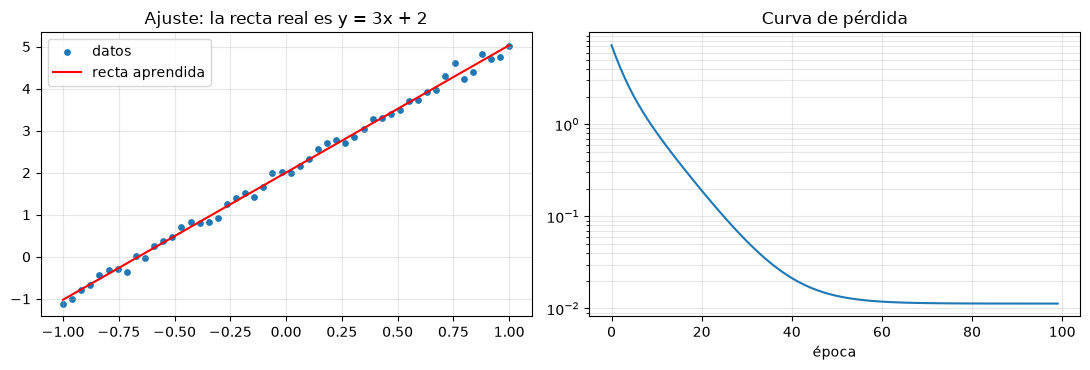

In [22]:
torch.manual_seed(0)
x_data = torch.linspace(-1, 1, 50).unsqueeze(1)                 # (50,1): m=50 ejemplos (en FILAS), 1 característica
y_data = 3 * x_data + 2 + 0.1 * torch.randn_like(x_data)

w = torch.zeros(1, 1, requires_grad=True)
b = torch.zeros(1,    requires_grad=True)
lr = 0.1
historial = []

for epoch in range(100):
    y_pred = x_data @ w + b                                     # 1) forward
    loss = ((y_pred - y_data) ** 2).mean()                      # 2) J (MSE, media sobre los ejemplos)
    loss.backward()                                             # 3) backward (autograd)
    with torch.no_grad():                                       # 4) actualización  W := W − α dW
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_(); b.grad.zero_()                              # 5) limpiar gradientes
    historial.append(loss.item())                               # .item(): guardamos un NÚMERO, no un tensor con grafo
    if epoch % 25 == 0 or epoch == 99:
        print(f"época {epoch:>3} | J = {loss.item():.4f} | w = {w.item():.3f} | b = {b.item():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(x_data, y_data, s=15, label="datos"); axes[0].plot(x_data, (x_data @ w + b).detach(), "r", label="recta aprendida")
axes[0].set_title("Ajuste: la recta real es y = 3x + 2"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(historial); axes[1].set_yscale("log"); axes[1].set_title("Curva de pérdida"); axes[1].set_xlabel("época"); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

---
# Bloque 3 · `torch.nn`: capas y modelos

## 3.1 La idea de `nn.Module`

Un **`nn.Module`** es un contenedor que agrupa (1) **parámetros** ($W$, $b$) y (2) una función **`forward`** que dice cómo se calcula la salida. Es la pieza básica de toda red en PyTorch: las capas son `Module`s, y las redes también (un `Module` puede contener otros `Module`s).

Lo que `nn.Module` te da gratis:

- recoge **automáticamente todos los parámetros** (`model.parameters()`) para pasarlos al optimizador;
- los mueve juntos a GPU (`model.to(device)`) o a otro tipo (`.double()`);
- los guarda y carga (`state_dict`, Bloque 10);
- activa/desactiva comportamientos de entrenamiento (`model.train()` / `model.eval()`, Bloque 8).

## 3.2 `nn.Linear` = tu capa $W\,a+b$

`nn.Linear(n_in, n_out)` crea $W^{[l]}\in\mathbb R^{n^{[l]}\times n^{[l-1]}}$ y $b^{[l]}\in\mathbb R^{n^{[l]}}$ y calcula $XW^{T}+b$. Los parámetros son `requires_grad=True` por defecto.

In [23]:
torch.manual_seed(0)
capa = nn.Linear(in_features=3, out_features=4)
print(capa)
print("weight:", tuple(capa.weight.shape), "-> (n[l], n[l-1]): la misma forma que la W de tus apuntes")
print("bias  :", tuple(capa.bias.shape),   "-> (n[l],)  (en tus apuntes era (n[l], 1))")
print("¿requires_grad?", capa.weight.requires_grad, capa.bias.requires_grad)
print("nº de parámetros:", sum(p.numel() for p in capa.parameters()), "= 4·3 + 4")

X = torch.randn(5, 3)                         # 5 ejemplos, 3 características -> (m, n0)
Z = capa(X)                                   # equivale a capa.forward(X)
print("\nZ:", tuple(Z.shape), "| ¿Z == X Wᵀ + b?", torch.allclose(Z, X @ capa.weight.T + capa.bias))

# La fórmula de P de §4.1 (nº de parámetros) se cumple: red 784 -> 128 -> 10
mnist_mlp = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
print("\nParámetros de 784→128→10:", sum(p.numel() for p in mnist_mlp.parameters()), "(= 101 770 en §4.1)")

Linear(in_features=3, out_features=4, bias=True)
weight: (4, 3) -> (n[l], n[l-1]): la misma forma que la W de tus apuntes
bias  : (4,) -> (n[l],)  (en tus apuntes era (n[l], 1))
¿requires_grad? True True
nº de parámetros: 16 = 4·3 + 4

Z: (5, 4) | ¿Z == X Wᵀ + b? True

Parámetros de 784→128→10: 101770 (= 101 770 en §4.1)


## 3.3 Funciones de activación

Existen en **dos versiones** equivalentes: como *módulo* (`nn.ReLU()`, para colocar dentro de `nn.Sequential`) y como *función* (`F.relu`, para usar dentro de un `forward`). Las tres de tus apuntes más las que se usan hoy:

| Activación | Módulo | Función | Comentario |
|---|---|---|---|
| Sigmoide | `nn.Sigmoid()` | `torch.sigmoid` | salida binaria (¡pero ver Bloque 4!) |
| Tanh | `nn.Tanh()` | `torch.tanh` | centrada en cero |
| ReLU | `nn.ReLU()` | `F.relu` | estándar por defecto |
| Leaky ReLU | `nn.LeakyReLU(0.01)` | `F.leaky_relu` | evita neuronas muertas ($g'=0.01$ si $z<0$) |
| GELU | `nn.GELU()` | `F.gelu` | estándar en Transformers |
| SiLU / Swish | `nn.SiLU()` | `F.silu` | $z\,\sigma(z)$, redes modernas |
| Softmax | `nn.Softmax(dim=1)` | `F.softmax(z, dim=1)` | multiclase; **exige `dim`** |

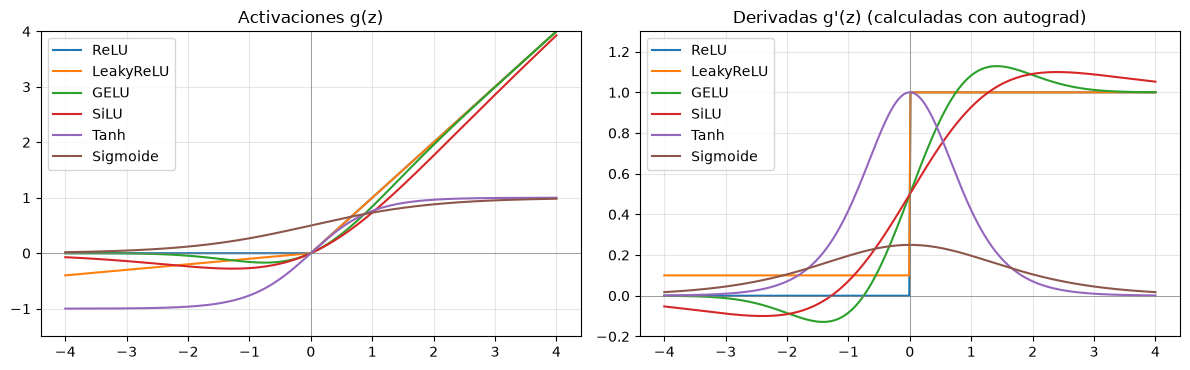

In [24]:
z = torch.linspace(-4, 4, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for nombre, f in [("ReLU", F.relu), ("LeakyReLU", lambda t: F.leaky_relu(t, 0.1)), ("GELU", F.gelu),
                  ("SiLU", F.silu), ("Tanh", torch.tanh), ("Sigmoide", torch.sigmoid)]:
    axes[0].plot(z, f(z), label=nombre)
    z_g = z.clone().requires_grad_(True)
    f(z_g).sum().backward()                            # ¡las derivadas las da autograd, no hace falta escribirlas!
    axes[1].plot(z, z_g.grad, label=nombre)
axes[0].set_title("Activaciones g(z)"); axes[1].set_title("Derivadas g'(z) (calculadas con autograd)")
for ax in axes: ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylim(-1.5, 4); axes[1].set_ylim(-0.2, 1.3)
plt.tight_layout(); plt.show()

## 3.4 `nn.Sequential`: capas en cadena

Para redes donde la salida de cada capa es la entrada de la siguiente (un MLP), `nn.Sequential` basta. Aquí el modelo del XOR del Bloque 6 de tus apuntes, `[2, 4, 1]`:

> **Importante:** el modelo **no incluye** la sigmoide final. Devuelve **logits** ($z^{[L]}$) y la pérdida `BCEWithLogitsLoss` (Bloque 4) aplica la sigmoide internamente de forma numéricamente estable.

In [25]:
modelo = nn.Sequential(
    nn.Linear(2, 4),       # capa 1: n0=2 -> n1=4    (W1: 4×2)
    nn.Tanh(),
    nn.Linear(4, 1),       # capa 2: n1=4 -> n2=1    (W2: 1×4)   [salida = logit z[2]]
)
print(modelo)
print("\nmodelo[0]:", modelo[0], "\n")
for nombre, p in modelo.named_parameters():
    print(f"{nombre:<10} forma {str(tuple(p.shape)):<8} nº = {p.numel()}")
print("\nTotal P =", sum(p.numel() for p in modelo.parameters()), " (§4.1: red 2→4→1 = 17 parámetros)")
print("Salida para 3 entradas:", modelo(torch.randn(3, 2)).shape)

Sequential(
  (0): Linear(in_features=2, out_features=4, bias=True)
  (1): Tanh()
  (2): Linear(in_features=4, out_features=1, bias=True)
)

modelo[0]: Linear(in_features=2, out_features=4, bias=True) 

0.weight   forma (4, 2)   nº = 8
0.bias     forma (4,)     nº = 4
2.weight   forma (1, 4)   nº = 4
2.bias     forma (1,)     nº = 1

Total P = 17  (§4.1: red 2→4→1 = 17 parámetros)
Salida para 3 entradas: torch.Size([3, 1])


## 3.5 Modelos propios: heredar de `nn.Module`

Cuando la arquitectura no es una simple cadena (conexiones residuales, varias ramas, lógica condicional…) escribes tu propia clase. Hay solo dos reglas: llamar a `super().__init__()` y definir `forward`. **Esta es la versión PyTorch de tu clase `NeuralNetwork` del Bloque 6:**

In [26]:
class MLP(nn.Module):
    '''Equivalente de tu clase NeuralNetwork: layer_sizes = [n0, n1, ..., nL] (devuelve logits).'''
    def __init__(self, layer_sizes, activation=nn.Tanh):
        super().__init__()                                    # ¡imprescindible!
        capas = []
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            capas += [nn.Linear(n_in, n_out), activation()]
        self.red = nn.Sequential(*capas[:-1])                 # quitamos la última activación (salida = logits)

    def forward(self, x):                                     # define el cálculo; se invoca con modelo(x)
        return self.red(x)

mlp = MLP([3, 5, 4, 1], activation=nn.ReLU)
print(mlp)
print("\nP =", sum(p.numel() for p in mlp.parameters()), "(§4.1: red 3→5→4→1 = 49 parámetros)")

MLP(
  (red): Sequential(
    (0): Linear(in_features=3, out_features=5, bias=True)
    (1): ReLU()
    (2): Linear(in_features=5, out_features=4, bias=True)
    (3): ReLU()
    (4): Linear(in_features=4, out_features=1, bias=True)
  )
)

P = 49 (§4.1: red 3→5→4→1 = 49 parámetros)


### ⚠️ Registro de submódulos: `nn.ModuleList` y `nn.Parameter`

`nn.Module` solo "ve" los submódulos y parámetros que **asignas como atributos** y que son de tipo `Module`/`Parameter`. Una **lista normal de Python** *no* se registra, y entonces `model.parameters()` queda vacío: ¡el optimizador no tendría nada que entrenar y **no daría error**!

In [27]:
class Mal(nn.Module):
    def __init__(self):
        super().__init__()
        self.capas = [nn.Linear(2, 2), nn.Linear(2, 1)]                 # lista normal de Python  ✗

class Bien(nn.Module):
    def __init__(self):
        super().__init__()
        self.capas = nn.ModuleList([nn.Linear(2, 2), nn.Linear(2, 1)])  # ModuleList  ✓

print("parámetros registrados  Mal:", len(list(Mal().parameters())), "| Bien:", len(list(Bien().parameters())))

parámetros registrados  Mal: 0 | Bien: 4


También puedes definir **tus propios parámetros** con `nn.Parameter` (un tensor con `requires_grad=True` que `nn.Module` registra solo). Reescribimos `nn.Linear` a mano, con la inicialización Xavier de §6.1:

In [28]:
class MiLineal(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        self.W = nn.Parameter(torch.randn(n_out, n_in) * (1.0 / n_in) ** 0.5)   # (n_out, n_in)  como en tus apuntes
        self.b = nn.Parameter(torch.zeros(n_out))
    def forward(self, x):
        return x @ self.W.T + self.b                                            # Z = X Wᵀ + b

torch.manual_seed(0)
mi, oficial = MiLineal(3, 4), nn.Linear(3, 4)
with torch.no_grad():
    oficial.weight.copy_(mi.W); oficial.bias.copy_(mi.b)
X = torch.randn(5, 3)
print("parámetros de MiLineal:", [n for n, _ in mi.named_parameters()])
print("¿MiLineal == nn.Linear?", torch.allclose(mi(X), oficial(X)))

parámetros de MiLineal: ['W', 'b']
¿MiLineal == nn.Linear? True


## 3.6 Inspeccionar un modelo

| Método | Devuelve |
|---|---|
| `model.parameters()` | todos los parámetros (lo que recibe el optimizador) |
| `model.named_parameters()` | pares (nombre, parámetro) |
| `model.state_dict()` | diccionario nombre → tensor (para guardar/cargar) |
| `model.children()` / `model.modules()` | submódulos directos / todos |
| `p.requires_grad_(False)` | **congela** un parámetro (no se entrena) |
| `model.train()` / `model.eval()` | modo entrenamiento / evaluación |
| `model.to(device)`, `.double()` | cambiar dispositivo / dtype de todos los parámetros |

In [29]:
print("state_dict:")
for k, v in modelo.state_dict().items():
    print(f"  {k:<10} {tuple(v.shape)}")

# Congelar la primera capa (útil en transfer learning)
for p in modelo[0].parameters():
    p.requires_grad_(False)
entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(f"\nCon la capa 1 congelada, parámetros entrenables: {entrenables} de {sum(p.numel() for p in modelo.parameters())}")
for p in modelo[0].parameters():
    p.requires_grad_(True)                                  # descongelamos

state_dict:
  0.weight   (4, 2)
  0.bias     (4,)
  2.weight   (1, 4)
  2.bias     (1,)

Con la capa 1 congelada, parámetros entrenables: 5 de 17


## 3.7 Inicialización de pesos

`nn.Linear` inicializa por defecto con una uniforme $U(-1/\sqrt{n_{in}},\,1/\sqrt{n_{in}})$. Para controlar la inicialización usa `torch.nn.init` (las funciones terminadas en `_` modifican en sitio):

| Función | Varianza de $W$ | Úsala con |
|---|---|---|
| `nn.init.xavier_normal_` | $\dfrac{2}{n_{in}+n_{out}}$ (Glorot) | tanh, sigmoide |
| `nn.init.kaiming_normal_(nonlinearity="relu")` | $\dfrac{2}{n_{in}}$ (**He**, la de §6.1) | ReLU |
| `nn.init.zeros_` | $0$ | sesgos |

(Matiz: el "Xavier" de tus apuntes usaba $1/n_{in}$; el de PyTorch es la versión de Glorot que promedia entrada y salida. El objetivo —que la señal no crezca ni se apague— es el mismo, §5.3.8.)

In [30]:
capa = nn.Linear(1000, 1000)
print(f"defecto (uniforme)     : std = {capa.weight.std().item():.4f}   (≈ 1/√(3·n_in) = {(1/3000)**0.5:.4f})")
nn.init.kaiming_normal_(capa.weight, nonlinearity="relu")
print(f"kaiming_normal_ (He)   : std = {capa.weight.std().item():.4f}   (√(2/n_in)      = {(2/1000)**0.5:.4f})")
nn.init.xavier_normal_(capa.weight)
print(f"xavier_normal_ (Glorot): std = {capa.weight.std().item():.4f}   (√(2/(n_in+n_out)) = {(2/2000)**0.5:.4f})")

# Aplicar una inicialización a TODO un modelo con .apply()
def init_pesos(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)
modelo.apply(init_pesos)
print("\nsesgos tras init:", modelo[0].bias.data)

defecto (uniforme)     : std = 0.0183   (≈ 1/√(3·n_in) = 0.0183)
kaiming_normal_ (He)   : std = 0.0447   (√(2/n_in)      = 0.0447)
xavier_normal_ (Glorot): std = 0.0316   (√(2/(n_in+n_out)) = 0.0316)

sesgos tras init: tensor([0., 0., 0., 0.])


## 3.8 Verificación: tu red $2\to2\to1$ como `nn.Sequential`

Cargamos *exactamente* los pesos del Bloque 3 de tus apuntes en un `nn.Sequential` y comprobamos el forward, la pérdida y los gradientes de §5.4. Esta función `red_apuntes()` la reutilizaremos en el Bloque 5.

In [31]:
def red_apuntes():
    '''Red 2→2→1 con sigmoide, con los pesos del Bloque 3 de tus apuntes (en float64). Devuelve (red, x, y).'''
    red = nn.Sequential(nn.Linear(2, 2), nn.Sigmoid(), nn.Linear(2, 1), nn.Sigmoid()).double()
    with torch.no_grad():
        red[0].weight.copy_(torch.tensor([[0.2, -0.3], [0.4, 0.1]])); red[0].bias.copy_(torch.tensor([0.1, -0.1]))
        red[2].weight.copy_(torch.tensor([[0.3, -0.2]]));              red[2].bias.copy_(torch.tensor([0.05]))
    x = torch.tensor([[1.0, 0.5]], dtype=torch.float64)       # (1,2): UN ejemplo, en una FILA
    y = torch.tensor([[1.0]],      dtype=torch.float64)
    return red, x, y

red, x_t, y_t = red_apuntes()
y_hat = red(x_t)
loss = 0.5 * ((y_hat - y_t) ** 2).sum()                       # MSE con el factor ½ de tus apuntes
loss.backward()

print(f"ŷ = {y_hat.item():.5f} (apuntes: 0.52346)   ℒ = {loss.item():.5f} (apuntes: 0.11355)")
print("dW2 =", red[2].weight.grad.numpy().ravel(), "  | apuntes [-0.06389 -0.06973]")
print("db2 =", red[2].bias.grad.numpy(),          "  | apuntes [-0.11887]")
print("dW1 =\n", red[0].weight.grad.numpy(),      "\n  | apuntes [[-0.00887 -0.00443] [ 0.00577  0.00288]]")
print("db1 =", red[0].bias.grad.numpy(),          "  | apuntes [-0.00887  0.00577]")

ŷ = 0.52346 (apuntes: 0.52346)   ℒ = 0.11355 (apuntes: 0.11355)
dW2 = [-0.06389 -0.06973]   | apuntes [-0.06389 -0.06973]
db2 = [-0.11887]   | apuntes [-0.11887]
dW1 =
 [[-0.00887 -0.00443]
 [ 0.00577  0.00288]] 
  | apuntes [[-0.00887 -0.00443] [ 0.00577  0.00288]]
db1 = [-0.00887  0.00577]   | apuntes [-0.00887  0.00577]


---
# Bloque 4 · Funciones de pérdida

## 4.1 Cómo se usa una pérdida: `criterion(salida, objetivo)`

Las pérdidas de `torch.nn` son módulos que se llaman como una función: `loss = criterion(salida_del_modelo, etiquetas)`. Devuelven un **tensor escalar** (con su grafo, listo para `backward()`).

El argumento **`reduction`** es *exactamente* la diferencia entre $\mathcal L$ y $J$ de §4.1:

| `reduction=` | Resultado | En tus apuntes |
|---|---|---|
| `"none"` | un valor **por ejemplo**, forma `(m,)` | $\mathcal L^{(i)}$ |
| `"mean"` (**por defecto**) | la media sobre los ejemplos, escalar | $J=\frac1m\sum_i\mathcal L^{(i)}$ |
| `"sum"` | la suma, escalar | $\sum_i\mathcal L^{(i)}$ (el gradiente crece con $m$) |

Repetimos el ejemplo de §4.1 ($m=3$, $\hat y=[0.9,0.2,0.6]$, $y=[1,0,0]$), donde obtuviste $J=0.41493$ y $\partial J/\partial b=0.2333$:

In [32]:
y_hat = torch.tensor([0.9, 0.2, 0.6]); y = torch.tensor([1., 0., 0.])
print("ℒ por ejemplo (reduction='none'):", nn.BCELoss(reduction="none")(y_hat, y))
print("J = media     (reduction='mean'):", nn.BCELoss(reduction="mean")(y_hat, y).item())
print("Σℒ            (reduction='sum') :", nn.BCELoss(reduction="sum")(y_hat, y).item())

# El gradiente respecto del sesgo de salida b (el mismo experimento de §4.1)
z0 = torch.log(y_hat / (1 - y_hat))                        # logits que producirían esas probabilidades
for red_ in ("mean", "sum"):
    b = torch.zeros(1, requires_grad=True)
    F.binary_cross_entropy_with_logits(z0 + b, y, reduction=red_).backward()
    print(f"reduction='{red_}':  ∂/∂b = {b.grad.item():.5f}")
print("→ con 'sum' el gradiente es m=3 veces mayor: habría que reajustar α al cambiar el tamaño del dataset (§4.1).")

ℒ por ejemplo (reduction='none'): tensor([0.10536, 0.22314, 0.91629])
J = media     (reduction='mean'): 0.41493162512779236
Σℒ            (reduction='sum') : 1.2447948455810547
reduction='mean':  ∂/∂b = 0.23333
reduction='sum':  ∂/∂b = 0.70000
→ con 'sum' el gradiente es m=3 veces mayor: habría que reajustar α al cambiar el tamaño del dataset (§4.1).


## 4.2 `nn.MSELoss` — ¡ojo con el factor ½!

`nn.MSELoss` calcula $\operatorname{media}\bigl((\hat y-y)^2\bigr)$ **sin** el $\tfrac12$ que usaste en tus apuntes. Por tanto da **el doble** de pérdida y de gradiente. No es un error: es solo una constante que `α` absorbe; pero conviene saberlo al comparar con tus resultados.

$$\mathcal L_{\text{tus apuntes}}=\tfrac12(\hat y-y)^2\ \Rightarrow\ \tfrac{\partial\mathcal L}{\partial\hat y}=\hat y-y\qquad\qquad\mathcal L_{\text{torch}}=(\hat y-y)^2\ \Rightarrow\ \tfrac{\partial\mathcal L}{\partial\hat y}=2(\hat y-y)$$

In [33]:
def pierde_y_deriva(f):
    p = torch.tensor(0.52346, requires_grad=True)          # la ŷ de tu §4.5
    perdida = f(p)
    (g,) = torch.autograd.grad(perdida, p)
    return perdida.item(), g.item()

objetivo = torch.tensor(1.0)
l1, g1 = pierde_y_deriva(lambda p: 0.5 * (p - objetivo) ** 2)
l2, g2 = pierde_y_deriva(lambda p: nn.MSELoss()(p, objetivo))
print(f"tus apuntes  ½(ŷ−y)²: ℒ = {l1:.5f} (§4.5: 0.11355)   dℒ/dŷ = {g1:+.5f}")
print(f"nn.MSELoss    (ŷ−y)²: ℒ = {l2:.5f}                  dℒ/dŷ = {g2:+.5f}   (el doble)")

tus apuntes  ½(ŷ−y)²: ℒ = 0.11355 (§4.5: 0.11355)   dℒ/dŷ = -0.47654
nn.MSELoss    (ŷ−y)²: ℒ = 0.22709                  dℒ/dŷ = -0.95308   (el doble)


## 4.3 `BCELoss` frente a `BCEWithLogitsLoss` (la que **debes** usar)

Hay dos formas de hacer clasificación binaria:

| | Salida del modelo | Pérdida |
|---|---|---|
| ❌ Ingenua | `nn.Sigmoid()` → probabilidad $\hat y$ | `nn.BCELoss` |
| ✅ **Recomendada** | **logit** $z$ (sin sigmoide) | **`nn.BCEWithLogitsLoss`** |

`BCEWithLogitsLoss` fusiona la sigmoide y la entropía cruzada en una fórmula **numéricamente estable**. Partiendo de $\mathcal L=-\bigl[y\log\sigma(z)+(1-y)\log(1-\sigma(z))\bigr]$ y simplificando:

$$\mathcal L(z,y)=\log\bigl(1+e^{z}\bigr)-y\,z\;=\;\max(z,0)-z\,y+\log\bigl(1+e^{-|z|}\bigr)$$

La última forma no desborda nunca. Con la versión ingenua, si $|z|$ es grande, $\sigma(z)$ se redondea a exactamente $0$ o $1$ y $\log(0)=-\infty$. Además, esta fusión es lo que da el gradiente limpio de §4.4:

$$\frac{\partial\mathcal L}{\partial z}=\sigma(z)-y\;=\;\hat y-y$$

In [34]:
# Un logit enorme con la etiqueta equivocada: ℒ debería ser ≈ 100
z = torch.tensor([100.0]); y = torch.tensor([0.0])
p = torch.sigmoid(z)                                       # = 1.0 exacto en float32
ingenua = -(y * torch.log(p) + (1 - y) * torch.log(1 - p))
print("σ(100)               =", p.item())
print("fórmula ingenua      =", ingenua.item(), "  (-(0·log 1 + 1·log 0) = ∞)")
print("BCEWithLogitsLoss    =", F.binary_cross_entropy_with_logits(z, y).item(), "  (≈ 100 ✓)")

# El gradiente de §4.4:  ∂ℒ/∂z = ŷ − y
z = torch.tensor([-1.2, 0.3, 2.0], requires_grad=True); y = torch.tensor([1., 0., 1.])
F.binary_cross_entropy_with_logits(z, y, reduction="sum").backward()
print("\nautograd  ∂ℒ/∂z:", z.grad)
print("σ(z) − y        :", (torch.sigmoid(z) - y).detach())

σ(100)               = 1.0
fórmula ingenua      = inf   (-(0·log 1 + 1·log 0) = ∞)
BCEWithLogitsLoss    = 100.0   (≈ 100 ✓)

autograd  ∂ℒ/∂z: tensor([-0.76852,  0.57444, -0.11920])
σ(z) − y        : tensor([-0.76852,  0.57444, -0.11920])


## 4.4 `nn.CrossEntropyLoss` (multiclase)

Para $C$ clases la red devuelve **$C$ logits** por ejemplo. La **softmax** los convierte en probabilidades y la entropía cruzada penaliza $-\log$ de la probabilidad de la clase correcta $k=y$:

$$p_k=\frac{e^{z_k}}{\sum_{j=1}^{C}e^{z_j}},\qquad\mathcal L=-\log p_{y}=-z_y+\log\sum_je^{z_j}\qquad\Longrightarrow\qquad\boxed{\frac{\partial\mathcal L}{\partial z_k}=p_k-\mathbb 1[k=y]}$$

Es la **generalización de $\hat y-y$** de tus apuntes: "probabilidad predicha menos objetivo (*one-hot*)". Reglas de uso de `CrossEntropyLoss`:

1. Entrada: **logits** crudos `(m, C)`. **No** apliques softmax antes (ya la lleva dentro).
2. Objetivo: **índices de clase** `(m,)` de tipo **`long`** (0, 1, …, C−1), *no* one-hot.

**Ejemplo** con 3 clases: logits $z=[2.0,\,1.0,\,0.1]$ y clase correcta $0$.

In [35]:
logits = torch.tensor([[2.0, 1.0, 0.1]], requires_grad=True)     # (m=1, C=3)
target = torch.tensor([0])                                       # índice de clase: LONG, forma (m,)
loss = F.cross_entropy(logits, target)
loss.backward()

p = F.softmax(logits, dim=1).detach()
print("softmax    :", p, "| suma =", p.sum().item())
print(f"ℒ = {loss.item():.5f}   = −log p[0] = {-torch.log(p[0, 0]).item():.5f}")
print("dz autograd      :", logits.grad)
print("dz = p − one_hot :", p - F.one_hot(target, 3))

# Error típico: aplicar softmax ANTES de la pérdida (softmax doble) -> resultado distinto y gradiente erróneo
mal = F.cross_entropy(F.softmax(logits, dim=1), target)
print(f"\nsoftmax doble (mal): ℒ = {mal.item():.5f}   (debería ser {loss.item():.5f})")

# Error típico: etiquetas float en lugar de long
try:
    F.cross_entropy(logits, torch.tensor([0.]))
except Exception as e:
    print("\nEtiquetas float ->", type(e).__name__, ":", str(e)[:100])

softmax    : tensor([[0.65900, 0.24243, 0.09857]]) | suma = 1.0000001192092896
ℒ = 0.41703   = −log p[0] = 0.41703
dz autograd      : tensor([[-0.34100,  0.24243,  0.09857]])
dz = p − one_hot : tensor([[-0.34100,  0.24243,  0.09857]])

softmax doble (mal): ℒ = 0.80212   (debería ser 0.41703)

Etiquetas float -> RuntimeError : expected target dtype to be Long or Byte, but got Float


## 4.5 Qué pérdida usar: tabla de decisión

| Tarea | Capa de salida | Pérdida | `target` (dtype, forma) | Predicción |
|---|---|---|---|---|
| **Regresión** | $k$ valores, **sin activación** | `MSELoss` (o `L1Loss`, `HuberLoss` si hay *outliers*) | `float` `(m, k)` | la salida |
| **Binaria** | **1 logit** | `BCEWithLogitsLoss` | `float` `(m,)` o `(m,1)`, **misma forma que la salida** | $\sigma(z)>0.5$ |
| **Multiclase** (1 de $C$) | $C$ logits | `CrossEntropyLoss` | **`long`** `(m,)` | `argmax(dim=1)` |
| **Multietiqueta** (varias a la vez) | $C$ logits | `BCEWithLogitsLoss` | `float` `(m, C)` con 0/1 | $\sigma(z)>0.5$ por columna |

Parámetros útiles: `CrossEntropyLoss(weight=..., label_smoothing=0.1)` (clases desbalanceadas / suavizado de etiquetas) y `BCEWithLogitsLoss(pos_weight=...)`.

⚠️ **La trampa de las formas.** Si `salida` es `(m,1)` y `target` es `(m,)`, la pérdida **hace broadcasting a $m\times m$ y no falla** (como mucho lanza un aviso). El resultado es un número que parece razonable pero es incorrecto:

In [36]:
import warnings
salida   = torch.tensor([[0.9], [0.2], [0.6]])      # (3,1)   <- lo que devuelve un modelo con n_L = 1
etiqueta = torch.tensor([1., 0., 0.])               # (3,)

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    mal = F.mse_loss(salida, etiqueta)              # broadcasting silencioso a (3,3)
print(f"formas (3,1) y (3,)  -> ℒ = {mal.item():.4f}   ✗")
print("   aviso de PyTorch:", str(avisos[0].message)[:100], "...")
print(f"formas (3,1) y (3,1) -> ℒ = {F.mse_loss(salida, etiqueta.unsqueeze(1)).item():.4f}   ✓")

formas (3,1) y (3,)  -> ℒ = 0.3589   ✗
   aviso de PyTorch: Using a target size (torch.Size([3])) that is different to the input size (torch.Size([3, 1])). This ...
formas (3,1) y (3,1) -> ℒ = 0.1367   ✓


---
# Bloque 5 · Optimizadores y *schedulers*

## 5.1 `torch.optim`: tu `update()` empaquetado

Un **optimizador** guarda una referencia a los parámetros y sabe actualizarlos con su `.grad`. Su API tiene solo dos métodos que vas a usar siempre:

| Método | Hace | En tus apuntes |
|---|---|---|
| `optimizer.zero_grad()` | pone a cero los `.grad` (que si no se acumulan, §2.4) | (en NumPy no hacía falta: `backward()` devolvía arrays nuevos) |
| `optimizer.step()` | aplica la regla de actualización usando `.grad` | `update()` |

Para `torch.optim.SGD` esa regla es exactamente la de §5.1:

$$\theta:=\theta-\alpha\,\nabla_\theta J$$

**Verificación:** repetimos el paso de descenso de §5.4 (MSE, $\alpha=0.5$) con `SGD` y comparamos con los pesos que obtuviste a mano.

In [37]:
red, x_t, y_t = red_apuntes()
opt = torch.optim.SGD(red.parameters(), lr=0.5)

perdida_antes = 0.5 * ((red(x_t) - y_t) ** 2).sum()
opt.zero_grad()
perdida_antes.backward()
opt.step()                                                  # θ := θ − α·∇θ

print("W2 =", red[2].weight.detach().numpy().ravel(), "| apuntes §5.4: [ 0.33194 -0.16513]")
print("b2 =", red[2].bias.detach().numpy(),            "| apuntes §5.4: [0.10944]")
print("W1 =\n", red[0].weight.detach().numpy(),         "\n   apuntes §5.4: [[ 0.20443 -0.29778] [ 0.39712  0.09856]]")
print("b1 =", red[0].bias.detach().numpy(),            "| apuntes §5.4: [ 0.10443 -0.10288]")

perdida_despues = 0.5 * ((red(x_t) - y_t) ** 2).sum()
print(f"\nℒ antes = {perdida_antes.item():.5f}   ℒ después = {perdida_despues.item():.5f}")
print("param_groups[0]['lr'] =", opt.param_groups[0]["lr"])

W2 = [ 0.33194 -0.16513] | apuntes §5.4: [ 0.33194 -0.16513]
b2 = [0.10944] | apuntes §5.4: [0.10944]
W1 =
 [[ 0.20443 -0.29778]
 [ 0.39712  0.09856]] 
   apuntes §5.4: [[ 0.20443 -0.29778] [ 0.39712  0.09856]]
b1 = [ 0.10443 -0.10288] | apuntes §5.4: [ 0.10443 -0.10288]

ℒ antes = 0.11355   ℒ después = 0.10221
param_groups[0]['lr'] = 0.5


## 5.2 Momentum

El descenso del gradiente simple zigzaguea en valles estrechos. **Momentum** acumula una "velocidad" como una bola rodando cuesta abajo, que suaviza el zigzag y acelera en las direcciones consistentes.

**Definición de PyTorch** (`SGD(lr=η, momentum=μ)`):

$$v_t=\mu\,v_{t-1}+g_t,\qquad\theta_t=\theta_{t-1}-\eta\,v_t$$

**Definición del ejercicio 4 de tus apuntes** (media móvil exponencial):

$$v_t=\beta\,v_{t-1}+(1-\beta)\,g_t,\qquad\theta_t=\theta_{t-1}-\alpha\,v_t$$

⚠️ **Son equivalentes salvo por una constante:** $v^{\text{apuntes}}=(1-\beta)\,v^{\text{torch}}$, de modo que `lr` de PyTorch $=\alpha\,(1-\beta)$ con $\mu=\beta$. Lo comprobamos minimizando $f(\theta)=\theta^2$ ($g=2\theta$):

In [38]:
def momentum_apuntes(theta0, alpha, beta, pasos):
    '''Ejercicio 4 de tus apuntes:  v := βv + (1−β)·dθ ;  θ := θ − αv   sobre f(θ)=θ².'''
    theta, v, tray = theta0, 0.0, [theta0]
    for _ in range(pasos):
        g = 2 * theta
        v = beta * v + (1 - beta) * g
        theta = theta - alpha * v
        tray.append(theta)
    return np.array(tray)

alpha, beta = 0.5, 0.9
tray_apuntes = momentum_apuntes(1.0, alpha, beta, 20)

p = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
opt = torch.optim.SGD([p], lr=alpha * (1 - beta), momentum=beta)       # lr_torch = α(1−β)
tray_torch = [p.item()]
for _ in range(20):
    opt.zero_grad(); (p ** 2).sum().backward(); opt.step(); tray_torch.append(p.item())

print("tus apuntes :", tray_apuntes[:6].round(5), "...")
print("torch SGD   :", np.array(tray_torch[:6]).round(5), "...")
print("¿idénticas?", np.allclose(tray_apuntes, tray_torch))

tus apuntes : [ 1.       0.9      0.72     0.486    0.2268  -0.02916] ...
torch SGD   : [ 1.       0.9      0.72     0.486    0.2268  -0.02916] ...
¿idénticas? True


## 5.3 Adam

**Adam** (*Adaptive Moment Estimation*) combina momentum con una **tasa de aprendizaje adaptada a cada parámetro**: divide el paso por la raíz de la media del gradiente al cuadrado. Los parámetros con gradientes grandes y ruidosos dan pasos pequeños; los de gradientes pequeños, pasos relativamente mayores.

$$\begin{aligned}
m_t&=\beta_1m_{t-1}+(1-\beta_1)\,g_t&&\text{(1er momento: media del gradiente)}\\
v_t&=\beta_2v_{t-1}+(1-\beta_2)\,g_t^{2}&&\text{(2º momento: media del gradiente al cuadrado)}\\
\hat m_t&=\frac{m_t}{1-\beta_1^{t}},\quad\hat v_t=\frac{v_t}{1-\beta_2^{t}}&&\text{(corrección de sesgo: }m_0=v_0=0\text{)}\\
\theta_t&=\theta_{t-1}-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\varepsilon}
\end{aligned}$$

Valores por defecto de PyTorch: $\eta=10^{-3}$, $(\beta_1,\beta_2)=(0.9,0.999)$, $\varepsilon=10^{-8}$. Es el optimizador "que funciona casi siempre" para empezar. Implementamos Adam a mano y lo comparamos con `torch.optim.Adam`:

In [39]:
def adam_manual(theta0, lr=0.1, b1=0.9, b2=0.999, eps=1e-8, pasos=5):
    theta, m, v = theta0, 0.0, 0.0
    tray = [theta]
    for t in range(1, pasos + 1):
        g = 2 * theta                                      # gradiente de f(θ) = θ²
        m = b1 * m + (1 - b1) * g
        v = b2 * v + (1 - b2) * g ** 2
        m_hat, v_hat = m / (1 - b1 ** t), v / (1 - b2 ** t)
        theta = theta - lr * m_hat / (v_hat ** 0.5 + eps)
        tray.append(theta)
    return tray

p = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
opt = torch.optim.Adam([p], lr=0.1)
tray_torch = [p.item()]
for _ in range(5):
    opt.zero_grad(); (p ** 2).sum().backward(); opt.step(); tray_torch.append(p.item())

print("Adam a mano  :", np.round(adam_manual(1.0), 6))
print("torch Adam   :", np.round(tray_torch, 6))
print("¿idénticos?", np.allclose(adam_manual(1.0), tray_torch))
print("\nNota: con Adam el primer paso mide ≈ lr SIEMPRE (m̂/√v̂ = ±1): el tamaño del paso no depende de la escala del gradiente.")

Adam a mano  : [1.      0.9     0.80041 0.70159 0.60394 0.50796]
torch Adam   : [1.      0.9     0.80041 0.70159 0.60394 0.50796]
¿idénticos? True

Nota: con Adam el primer paso mide ≈ lr SIEMPRE (m̂/√v̂ = ±1): el tamaño del paso no depende de la escala del gradiente.


## 5.4 Comparativa visual de optimizadores

| Optimizador | Idea | Cuándo |
|---|---|---|
| `SGD` | pasos proporcionales al gradiente | referencia; con momentum + *scheduler* sigue siendo el estándar en visión |
| `SGD(momentum=0.9)` | + velocidad | casi siempre mejor que SGD plano |
| `RMSprop` | divide por la raíz de la media de $g^2$ | RNN, problemas no estacionarios |
| **`Adam`** | momentum + paso adaptativo | **primera opción por defecto** |
| **`AdamW`** | Adam con *weight decay* desacoplado (§5.6) | Transformers y redes modernas |

Los ponemos a descender por un valle curvo, $f(x,y)=(1-x)^2+5\,(y-x^2)^2$ (mínimo en $(1,1)$), partiendo del mismo punto:

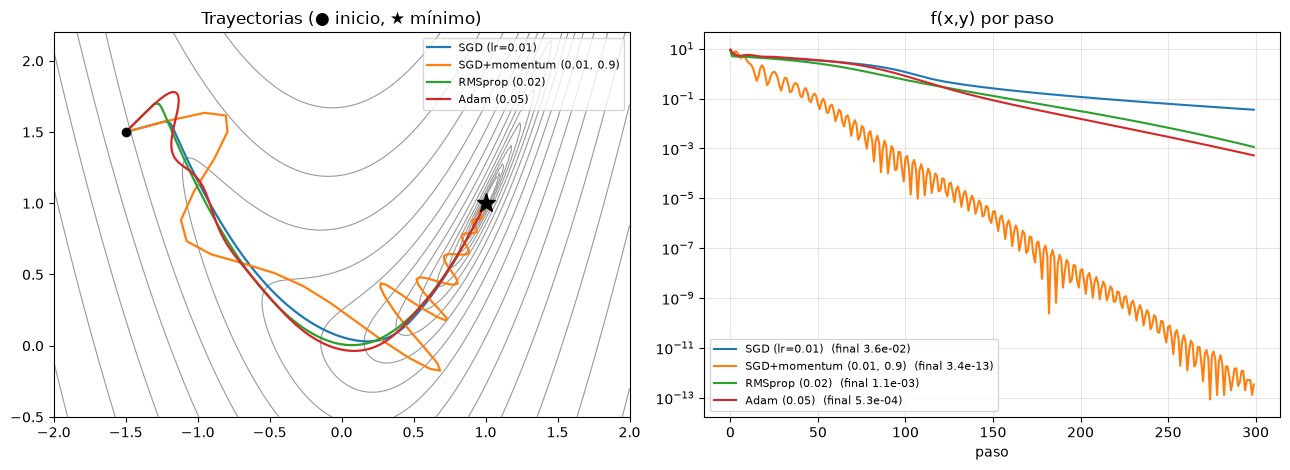

In [40]:
def f_valle(p):
    return (1 - p[0]) ** 2 + 5 * (p[1] - p[0] ** 2) ** 2

def descender(make_opt, pasos=300, inicio=(-1.5, 1.5)):
    p = torch.tensor(inicio, requires_grad=True)
    opt = make_opt([p])
    tray, perdidas = [p.detach().clone().numpy()], []
    for _ in range(pasos):
        opt.zero_grad(); loss = f_valle(p); loss.backward(); opt.step()
        tray.append(p.detach().clone().numpy()); perdidas.append(loss.item())
    return np.array(tray), perdidas

optimizadores = {
    "SGD (lr=0.01)":             lambda ps: torch.optim.SGD(ps, lr=0.01),
    "SGD+momentum (0.01, 0.9)":  lambda ps: torch.optim.SGD(ps, lr=0.01, momentum=0.9),
    "RMSprop (0.02)":            lambda ps: torch.optim.RMSprop(ps, lr=0.02),
    "Adam (0.05)":               lambda ps: torch.optim.Adam(ps, lr=0.05),
}
resultados_opt = {n: descender(mk) for n, mk in optimizadores.items()}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
xx, yy = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-0.5, 2.2, 200))
axes[0].contour(xx, yy, (1 - xx) ** 2 + 5 * (yy - xx ** 2) ** 2, levels=np.logspace(-2, 2.5, 18), colors="gray", linewidths=0.8, alpha=0.8)
for nombre, (tray, perd) in resultados_opt.items():
    axes[0].plot(tray[:, 0], tray[:, 1], lw=1.6, label=nombre)
    axes[1].plot(perd, label=f"{nombre}  (final {perd[-1]:.1e})")
axes[0].plot(1, 1, "k*", ms=14); axes[0].plot(-1.5, 1.5, "ko")
axes[0].set_title("Trayectorias (● inicio, ★ mínimo)"); axes[0].legend(fontsize=8)
axes[1].set_yscale("log"); axes[1].set_title("f(x,y) por paso"); axes[1].set_xlabel("paso"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

**Lectura:** el SGD plano es el más lento (el valle es estrecho y curvo). **Momentum** acumula velocidad, "se pasa" y oscila, pero es el que llega antes al mínimo en *este* problema. **RMSprop** y **Adam** avanzan sin zigzaguear porque escalan el paso por parámetro, pero con estas `lr` aún no han llegado. No hay un optimizador universalmente mejor: depende del problema y, sobre todo, de la `lr` (por eso se usan *schedulers*).

## 5.5 *Schedulers*: cambiar $\alpha$ durante el entrenamiento

Una tasa de aprendizaje grande al principio avanza rápido; una pequeña al final permite **asentarse** en el mínimo. Un *scheduler* modifica `lr` según el número de épocas (se llama a `scheduler.step()` **después** de `optimizer.step()`).

| Scheduler | Regla | Uso |
|---|---|---|
| `StepLR(step_size, gamma)` | $\alpha\leftarrow\gamma\alpha$ cada `step_size` épocas | clásico |
| `ExponentialLR(gamma)` | $\alpha_t=\alpha_0\gamma^t$ | suave |
| `CosineAnnealingLR(T_max)` | baja siguiendo medio coseno | muy habitual |
| `OneCycleLR(max_lr, total_steps)` | sube y luego baja | entrenamientos rápidos |
| `ReduceLROnPlateau` | divide $\alpha$ cuando la métrica **deja de mejorar** | `scheduler.step(val_loss)` |

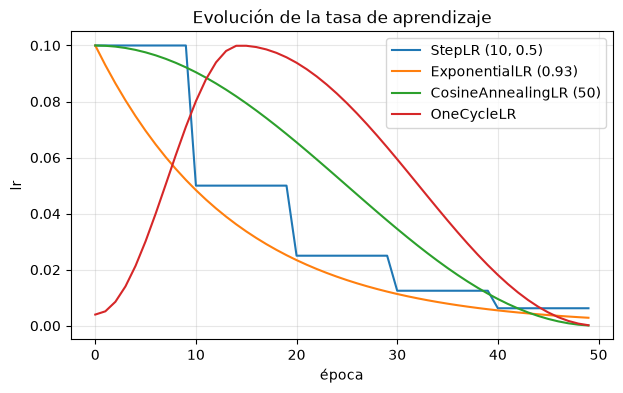

In [41]:
from torch.optim import lr_scheduler as S

def curva_lr(make_sched, epocas=50, lr0=0.1):
    p = nn.Parameter(torch.zeros(1)); opt = torch.optim.SGD([p], lr=lr0)
    sched = make_sched(opt); lrs = []
    for _ in range(epocas):
        lrs.append(opt.param_groups[0]["lr"])
        opt.step(); sched.step()
    return lrs

planes = {
    "StepLR (10, 0.5)":       lambda o: S.StepLR(o, step_size=10, gamma=0.5),
    "ExponentialLR (0.93)":   lambda o: S.ExponentialLR(o, gamma=0.93),
    "CosineAnnealingLR (50)": lambda o: S.CosineAnnealingLR(o, T_max=50),
    "OneCycleLR":             lambda o: S.OneCycleLR(o, max_lr=0.1, total_steps=51),
}
for nombre, mk in planes.items():
    plt.plot(curva_lr(mk), label=nombre)
plt.title("Evolución de la tasa de aprendizaje"); plt.xlabel("época"); plt.ylabel("lr"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 5.6 Grupos de parámetros, *weight decay* y recorte de gradientes

**Grupos de parámetros.** Puedes dar una `lr` distinta a cada parte del modelo (típico al *afinar* una red preentrenada: `lr` pequeña para el cuerpo y grande para la cabeza).

**Weight decay = regularización $L_2$.** En el ejercicio 3 de tus apuntes añadías $\frac{\lambda}{m}W$ al gradiente. `weight_decay=wd` hace exactamente $g\leftarrow g+wd\cdot\theta$, así que $wd=\lambda/m$. En **`AdamW`** el decaimiento se aplica *aparte* del paso adaptativo ($\theta\leftarrow\theta-\eta\,wd\,\theta$), que regulariza mejor que meterlo en el gradiente de Adam.

**Recorte de gradientes** (*gradient clipping*): contra gradientes que explotan (§5.3.8) se reescala el gradiente si su norma supera un umbral $c$:

$$g\leftarrow g\cdot\min\!\Bigl(1,\ \frac{c}{\lVert g\rVert}\Bigr)$$

In [42]:
# --- Grupos de parámetros ---
modelo_g = nn.Sequential(nn.Linear(2, 4), nn.Tanh(), nn.Linear(4, 1))
opt = torch.optim.SGD([{"params": modelo_g[0].parameters(), "lr": 0.1},
                       {"params": modelo_g[2].parameters(), "lr": 0.01}], lr=0.05, momentum=0.9)
print("lr de cada grupo:", [g["lr"] for g in opt.param_groups])

# --- weight_decay de SGD  ==  añadir wd·θ al gradiente ---
w_a = torch.tensor([1.0, -2.0], requires_grad=True); w_b = w_a.detach().clone().requires_grad_()
opt_a = torch.optim.SGD([w_a], lr=0.1, weight_decay=0.5)
(w_a * torch.tensor([3., 4.])).sum().backward(); opt_a.step()
(w_b * torch.tensor([3., 4.])).sum().backward()
with torch.no_grad(): w_b -= 0.1 * (w_b.grad + 0.5 * w_b)
print("\nweight_decay de SGD :", w_a.detach().numpy(), "| a mano (g + wd·θ):", w_b.detach().numpy())

# --- Recorte de la norma del gradiente ---
modelo_c = nn.Sequential(nn.Linear(2, 3), nn.Tanh(), nn.Linear(3, 1))
x_c, y_c = torch.randn(8, 2) * 10, torch.randn(8, 1) * 10
nn.MSELoss()(modelo_c(x_c), y_c).backward()
norma = lambda: torch.sqrt(sum((p.grad ** 2).sum() for p in modelo_c.parameters())).item()
antes = norma()
devuelve = nn.utils.clip_grad_norm_(modelo_c.parameters(), max_norm=1.0)   # devuelve la norma ORIGINAL
print(f"\n‖g‖ antes = {antes:.3f} | clip_grad_norm_ devuelve {devuelve.item():.3f} | ‖g‖ después = {norma():.3f}")

lr de cada grupo: [0.1, 0.01]

weight_decay de SGD : [ 0.65 -2.3 ] | a mano (g + wd·θ): [ 0.65 -2.3 ]

‖g‖ antes = 12.922 | clip_grad_norm_ devuelve 12.922 | ‖g‖ después = 1.000


---
# Bloque 6 · El bucle de entrenamiento: XOR en PyTorch

## 6.1 Las cinco líneas

Ya tenemos todas las piezas. Tu método `fit()` del Bloque 6 se convierte en estas cinco líneas, siempre en este orden:

| Paso | Tu `fit()` (NumPy) | PyTorch |
|:-:|---|---|
| 1 | `A_out = self.forward(X)` | `salida = modelo(X)` |
| 2 | `loss = self.compute_loss(A_out, Y)` | `loss = criterion(salida, y)` |
| 3 | *(no hacía falta)* | `optimizer.zero_grad()` |
| 4 | `dW, db = self.backward(Y)` | `loss.backward()` |
| 5 | `self.update(dW, db, lr)` | `optimizer.step()` |

## 6.2 El XOR del Bloque 6

Mismo problema y misma arquitectura `2 → 4 → 1` (tanh), `lr=0.5`, 5000 épocas, entropía cruzada binaria. Recuerda **la convención nueva**: `X` es `(4, 2)` (ejemplos en filas), no `(2, 4)`.

In [43]:
X_xor = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])      # (4,2)  ← traspuesta respecto a tus apuntes
y_xor = torch.tensor([[0.], [1.], [1.], [0.]])                      # (4,1)

torch.manual_seed(3)
modelo = nn.Sequential(nn.Linear(2, 4), nn.Tanh(), nn.Linear(4, 1))    # salida = logit
criterion = nn.BCEWithLogitsLoss()                                     # sigmoide + entropía cruzada (estable)
optimizer = torch.optim.SGD(modelo.parameters(), lr=0.5)

historial = []
for epoch in range(1, 5001):
    logits = modelo(X_xor)                       # 1) forward
    loss = criterion(logits, y_xor)              # 2) pérdida J
    optimizer.zero_grad()                        # 3) limpiar gradientes
    loss.backward()                              # 4) backward (autograd)
    optimizer.step()                             # 5) actualizar parámetros
    historial.append(loss.item())
    if epoch == 1 or epoch % 1000 == 0:
        print(f"Época {epoch:>6d} | pérdida = {loss.item():.6f}")

# --- Evaluación ---
modelo.eval()
with torch.no_grad():
    probs = torch.sigmoid(modelo(X_xor))         # el modelo devuelve LOGITS: la sigmoide se aplica a mano al predecir
    pred = (probs > 0.5).float()
print("\nProbabilidades:", probs.numpy().round(4).ravel())
print("Clases predichas:", pred.numpy().astype(int).ravel(), "| reales:", y_xor.numpy().astype(int).ravel())
print("Precisión:", (pred == y_xor).float().mean().item() * 100, "%")

Época      1 | pérdida = 0.690455
Época   1000 | pérdida = 0.005750
Época   2000 | pérdida = 0.002399
Época   3000 | pérdida = 0.001428
Época   4000 | pérdida = 0.000983
Época   5000 | pérdida = 0.000736

Probabilidades: [0.0009 0.9995 0.9993 0.0009]
Clases predichas: [0 1 1 0] | reales: [0 1 1 0]
Precisión: 100.0 %


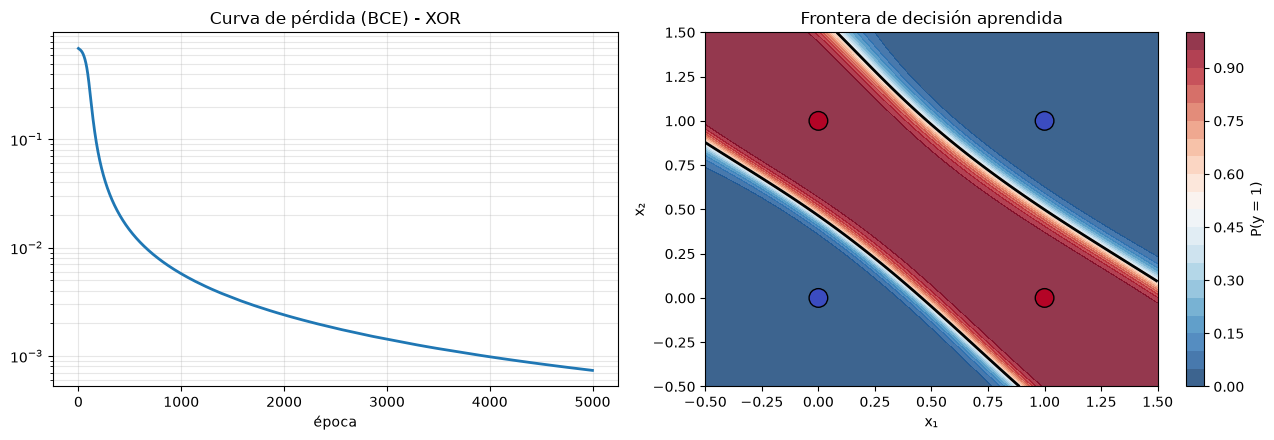

In [44]:
def frontera_binaria(modelo, X, y, ax, titulo=""):
    '''Dibuja P(y=1) de un modelo que devuelve LOGITS, junto con los puntos. Devuelve el contourf (para colorbar).'''
    X = np.asarray(X); y = np.asarray(y).ravel()
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    estaba_entrenando = modelo.training; modelo.eval()
    with torch.no_grad():
        probs = torch.sigmoid(modelo(grid)).reshape(xx.shape).numpy()
    modelo.train(estaba_entrenando)
    cs = ax.contourf(xx, yy, probs, levels=20, cmap="RdBu_r", alpha=0.8)
    ax.contour(xx, yy, probs, levels=[0.5], colors="k", linewidths=2)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=60 if len(y) > 20 else 180, zorder=3)
    ax.set_title(titulo); ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
    return cs

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(historial, lw=2); axes[0].set_yscale("log"); axes[0].set_title("Curva de pérdida (BCE) - XOR")
axes[0].set_xlabel("época"); axes[0].grid(alpha=0.3, which="both")
cs = frontera_binaria(modelo, X_xor, y_xor, axes[1], "Frontera de decisión aprendida")
plt.colorbar(cs, ax=axes[1], label="P(y = 1)")
plt.tight_layout(); plt.show()

## 6.3 ¿Es realmente *tu* algoritmo? Comparación paso a paso con NumPy

La prueba definitiva: partimos de **los mismos pesos iniciales**, entrenamos 200 épocas con **tu** retropropagación en NumPy y con PyTorch (`float64`), y comparamos los pesos finales. Si PyTorch es "tu código automatizado", deben coincidir hasta el error de redondeo.

> ⚠️ Los pesos de NumPy se **copian** (`.copy()`): `.numpy()` comparte memoria con el tensor, y al actualizar en sitio con `-=` estaríamos modificando también el modelo de PyTorch.

In [45]:
def entrenar_numpy(W1, b1, W2, b2, X, Y, epochs, lr):
    '''Tu NeuralNetwork de los apuntes, versión mínima (tanh -> sigmoide, BCE, lote completo). X:(n0,m), Y:(1,m).'''
    m = X.shape[1]
    for _ in range(epochs):
        A1 = np.tanh(W1 @ X + b1)
        A2 = 1 / (1 + np.exp(-(W2 @ A1 + b2)))
        dZ2 = A2 - Y                                              # sigmoide + CE  (§4.4)
        dW2 = dZ2 @ A1.T / m;  db2 = dZ2.sum(axis=1, keepdims=True) / m
        dZ1 = (W2.T @ dZ2) * (1 - A1 ** 2)                        # g'(z) para tanh
        dW1 = dZ1 @ X.T / m;   db1 = dZ1.sum(axis=1, keepdims=True) / m
        W1 -= lr * dW1; b1 -= lr * db1; W2 -= lr * dW2; b2 -= lr * db2
    return W1, b1, W2, b2

torch.manual_seed(5)
m_t = nn.Sequential(nn.Linear(2, 4), nn.Tanh(), nn.Linear(4, 1)).double()

# Pesos iniciales idénticos (¡copias!) en la convención de columnas de tus apuntes
W1n = m_t[0].weight.detach().numpy().copy();                 b1n = m_t[0].bias.detach().numpy().copy().reshape(-1, 1)
W2n = m_t[2].weight.detach().numpy().copy();                 b2n = m_t[2].bias.detach().numpy().copy().reshape(-1, 1)
Xn, Yn = X_xor.double().numpy().T, y_xor.double().numpy().T   # (2,4) y (1,4)

W1n, b1n, W2n, b2n = entrenar_numpy(W1n, b1n, W2n, b2n, Xn, Yn, epochs=200, lr=0.5)

opt = torch.optim.SGD(m_t.parameters(), lr=0.5); crit = nn.BCEWithLogitsLoss()
for _ in range(200):
    opt.zero_grad(); crit(m_t(X_xor.double()), y_xor.double()).backward(); opt.step()

dif = max(np.abs(W1n - m_t[0].weight.detach().numpy()).max(), np.abs(b1n.ravel() - m_t[0].bias.detach().numpy()).max(),
          np.abs(W2n - m_t[2].weight.detach().numpy()).max(), np.abs(b2n.ravel() - m_t[2].bias.detach().numpy()).max())
print(f"Máxima diferencia entre tus pesos (NumPy) y los de PyTorch tras 200 épocas: {dif:.2e}")
print("¿Mismo algoritmo?", dif < 1e-10)

Máxima diferencia entre tus pesos (NumPy) y los de PyTorch tras 200 épocas: 6.66e-16
¿Mismo algoritmo? True


## 6.4 Una función de entrenamiento reutilizable

Para no repetir el bucle, lo encapsulamos (versión de lote completo; en el Bloque 7 haremos la de mini-lotes):

In [46]:
def entrenar(modelo, X, y, criterion, optimizer, epochs, scheduler=None, imprimir_cada=None):
    '''Bucle de lote completo. Devuelve el historial de la pérdida.'''
    historial = []
    for epoch in range(1, epochs + 1):
        modelo.train()
        loss = criterion(modelo(X), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        if scheduler is not None:
            scheduler.step()
        historial.append(loss.item())
        if imprimir_cada and (epoch == 1 or epoch % imprimir_cada == 0):
            print(f"Época {epoch:>5d} | pérdida = {loss.item():.5f}")
    return historial

# Misma tarea con otro optimizador: Adam converge con muchas menos épocas
torch.manual_seed(3)
modelo_adam = nn.Sequential(nn.Linear(2, 4), nn.Tanh(), nn.Linear(4, 1))
h_adam = entrenar(modelo_adam, X_xor, y_xor, nn.BCEWithLogitsLoss(), torch.optim.Adam(modelo_adam.parameters(), lr=0.05),
                  epochs=500, imprimir_cada=100)
print("¿XOR resuelto con Adam en 500 épocas?", ((torch.sigmoid(modelo_adam(X_xor)) > 0.5).float() == y_xor).all().item())

Época     1 | pérdida = 0.69046
Época   100 | pérdida = 0.01372
Época   200 | pérdida = 0.00485
Época   300 | pérdida = 0.00265
Época   400 | pérdida = 0.00172
Época   500 | pérdida = 0.00122
¿XOR resuelto con Adam en 500 épocas? True


---
# Bloque 7 · Datos: `Dataset` y `DataLoader`

## 7.1 Por qué mini-lotes

En tus apuntes cada paso de descenso usaba **todos** los ejemplos (lote completo). Con millones de ejemplos eso es lentísimo e inviable en memoria. La alternativa: calcular el gradiente con un **mini-lote** de $B$ ejemplos (típicamente 32–512):

$$J_B(\theta)=\frac1B\sum_{i\in\text{lote}}\mathcal L^{(i)}\qquad\Longrightarrow\qquad\mathbb E\bigl[\nabla J_B\bigr]=\nabla J$$

El gradiente del mini-lote es una **estimación insesgada y ruidosa** del gradiente completo: más barata y, además, el ruido ayuda a escapar de mínimos malos.

| Término | Significado |
|---|---|
| **Época** | una pasada completa por todos los datos |
| **Iteración** (paso) | una actualización de parámetros con un lote |
| Iteraciones por época | $\lceil m/B\rceil$ |

| Variante | $B$ | Pasos | Ruido |
|---|---|---|---|
| Lote completo (tus apuntes) | $m$ | pocos, caros | ninguno |
| **Mini-lote** | $32\ldots512$ | muchos, baratos | moderado |
| SGD "puro" | $1$ | muchísimos | máximo |

## 7.2 `TensorDataset` y `DataLoader`

- **`Dataset`**: sabe decir cuántos ejemplos hay (`len`) y devolver el $i$-ésimo (`ds[i]`).
- **`DataLoader`**: envuelve un `Dataset` y va entregando **lotes** (ya apilados en tensores), barajando en cada época si `shuffle=True`.

In [47]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split

X_demo = torch.arange(10.).unsqueeze(1)                  # 10 ejemplos de 1 característica
y_demo = torch.arange(10) % 2
ds = TensorDataset(X_demo, y_demo)
print("len(ds) =", len(ds), "| ds[3] =", ds[3])

print("\nshuffle=False, batch_size=4  (m=10 -> lotes de 4, 4 y 2):")
for i, (xb, yb) in enumerate(DataLoader(ds, batch_size=4, shuffle=False)):
    print(f"  lote {i}: x = {xb.squeeze(1).tolist()}   y = {yb.tolist()}   forma de x: {tuple(xb.shape)}")

g = torch.Generator().manual_seed(0)                      # barajado reproducible
print("\nshuffle=True  (cambia en cada época):")
loader = DataLoader(ds, batch_size=4, shuffle=True, generator=g)
for epoca in range(2):
    print(f"  época {epoca}:", [xb.squeeze(1).tolist() for xb, _ in loader])
print("\ndrop_last=True descarta el último lote incompleto:", len(DataLoader(ds, batch_size=4, drop_last=True)), "lotes")

# ¡Cuidado al promediar la pérdida por época! El último lote es más pequeño
perdida_i = torch.arange(10.)                             # supón que ℒ⁽ⁱ⁾ = 0,1,...,9  ->  J verdadero = 4.5
medias = [lote[0].mean().item() for lote in DataLoader(TensorDataset(perdida_i), batch_size=4)]
tamaños = [4, 4, 2]
print(f"\nmedia de las medias por lote = {np.mean(medias):.4f}  ✗")
print(f"media PONDERADA por tamaño   = {np.average(medias, weights=tamaños):.4f}  ✓ (J verdadero = 4.5)")

len(ds) = 10 | ds[3] = (tensor([3.]), tensor(1))

shuffle=False, batch_size=4  (m=10 -> lotes de 4, 4 y 2):
  lote 0: x = [0.0, 1.0, 2.0, 3.0]   y = [0, 1, 0, 1]   forma de x: (4, 1)
  lote 1: x = [4.0, 5.0, 6.0, 7.0]   y = [0, 1, 0, 1]   forma de x: (4, 1)
  lote 2: x = [8.0, 9.0]   y = [0, 1]   forma de x: (2, 1)

shuffle=True  (cambia en cada época):
  época 0: [[3.0, 7.0, 5.0, 2.0], [0.0, 8.0, 1.0, 6.0], [9.0, 4.0]]
  época 1: [[1.0, 3.0, 2.0, 7.0], [5.0, 9.0, 0.0, 6.0], [4.0, 8.0]]

drop_last=True descarta el último lote incompleto: 2 lotes

media de las medias por lote = 5.1667  ✗
media PONDERADA por tamaño   = 4.5000  ✓ (J verdadero = 4.5)


> **Regla:** al acumular la pérdida de una época, pondera cada lote por su tamaño ($\bar J=\sum_b|B_b|\,J_b\,/\,m$), como haremos en nuestra función de entrenamiento.

Opciones útiles de `DataLoader`: `num_workers` (procesos de carga en paralelo; usa `0` en notebooks/Windows), `pin_memory=True` (acelera la copia a GPU), `collate_fn` (cómo se apilan ejemplos de longitud variable).

## 7.3 `Dataset` propio

Para datos que no caben en un tensor (imágenes en disco, texto…), heredas de `Dataset` e implementas **`__len__`** y **`__getitem__`**; la carga y las transformaciones se hacen *bajo demanda*, ejemplo a ejemplo.

In [48]:
class DatasetTabular(Dataset):
    '''Dataset mínimo: guarda X, y y aplica una transformación opcional a cada ejemplo al pedirlo.'''
    def __init__(self, X, y, transform=None):
        self.X, self.y, self.transform = torch.as_tensor(X), torch.as_tensor(y), transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = self.X[i]
        if self.transform: x = self.transform(x)
        return x, self.y[i]

ruido = lambda x: x + 0.1 * torch.randn_like(x)             # 'data augmentation' sencilla
ds_ruido = DatasetTabular(torch.zeros(6, 2), torch.arange(6), transform=ruido)
xb, yb = next(iter(DataLoader(ds_ruido, batch_size=3)))
print("lote con ruido añadido al vuelo:\n", xb, "\netiquetas:", yb)

lote con ruido añadido al vuelo:
 tensor([[ 0.09684,  0.06749],
        [ 0.06594, -0.21392],
        [-0.09621,  0.03713]]) 
etiquetas: tensor([0, 1, 2])


## 7.4 Preparar los datos: partición y normalización

Usaremos el clásico **dos lunas** (`make_moons`): clasificación binaria no lineal, como el XOR pero con ruido y 1000 puntos. Reglas de oro:

1. **Tres particiones:** *entrenamiento* (ajusta parámetros), *validación* (elige hiperparámetros y detecta sobreajuste) y *test* (nota final, **se mira una sola vez**).
2. **Normaliza** las características a media 0 y desviación 1 (las redes entrenan mucho mejor), **calculando $\mu,\sigma$ solo con el entrenamiento**. Calcularlos con todos los datos es *fuga de información* (*data leakage*): el test influye en el entrenamiento.

tamaños  train/val/test: 600 200 200
media y std de train tras normalizar: [-0. -0.] [1. 1.]
iteraciones por época: 19 = ⌈600/32⌉


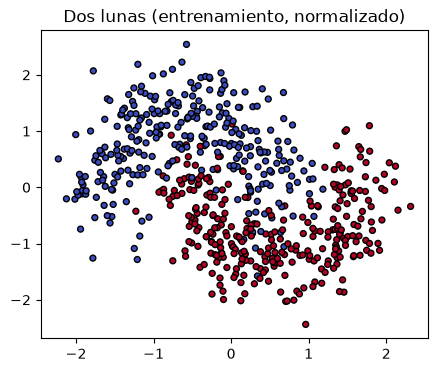

In [49]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X_all, y_all = make_moons(n_samples=1000, noise=0.25, random_state=0)
X_tmp, X_te, y_tmp, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=0, stratify=y_all)
X_tr, X_val, y_tr, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=0, stratify=y_tmp)   # 60/20/20

mu, sigma = X_tr.mean(axis=0), X_tr.std(axis=0)             # SOLO con entrenamiento
estandariza = lambda X: ((X - mu) / sigma).astype(np.float32)
X_tr, X_val, X_te = estandariza(X_tr), estandariza(X_val), estandariza(X_te)
y_tr, y_val, y_te = (v.astype(np.float32) for v in (y_tr, y_val, y_te))

print("tamaños  train/val/test:", len(y_tr), len(y_val), len(y_te))
print("media y std de train tras normalizar:", X_tr.mean(0).round(3), X_tr.std(0).round(3))

make_ds = lambda X, y: TensorDataset(torch.from_numpy(X), torch.from_numpy(y).unsqueeze(1))   # y -> (m,1) float
ds_tr, ds_val, ds_te = make_ds(X_tr, y_tr), make_ds(X_val, y_val), make_ds(X_te, y_te)
loader_tr  = DataLoader(ds_tr,  batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(0))
loader_val = DataLoader(ds_val, batch_size=256)
loader_te  = DataLoader(ds_te,  batch_size=256)
print("iteraciones por época:", len(loader_tr), "= ⌈600/32⌉")

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="coolwarm", edgecolors="k", s=18); ax.set_title("Dos lunas (entrenamiento, normalizado)")
plt.show()

## 7.5 Entrenar con mini-lotes: la función estándar

Ahora el bucle tiene **dos niveles**: épocas y lotes. Dentro de cada época: `train()` → recorrer lotes (con paso de optimización) → `eval()` + `no_grad()` para medir en validación.

In [50]:
def metricas_lote(salida, y):
    '''Aciertos de un lote: binaria (1 logit, logit>0 ⇔ σ>0.5) o multiclase (argmax).'''
    pred = (salida > 0).float() if salida.shape[1] == 1 else salida.argmax(dim=1)
    return (pred == y).sum().item()

def evaluar(modelo, loader, criterion, device="cpu"):
    modelo.eval()                                           # desactiva dropout / BN en modo evaluación
    perdida, aciertos, n = 0.0, 0, 0
    with torch.no_grad():                                   # sin grafo: más rápido y menos memoria
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            salida = modelo(xb)
            perdida += criterion(salida, yb).item() * len(xb)      # ponderado por el tamaño del lote
            aciertos += metricas_lote(salida, yb); n += len(xb)
    return perdida / n, aciertos / n

def entrenar_loader(modelo, loader_tr, loader_val, criterion, optimizer, epochs, scheduler=None, device="cpu", verbose=True):
    hist = {"tr_loss": [], "val_loss": [], "tr_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        modelo.train()
        suma, aciertos, n = 0.0, 0, 0
        for xb, yb in loader_tr:                            # ← bucle sobre mini-lotes
            xb, yb = xb.to(device), yb.to(device)
            salida = modelo(xb)
            loss = criterion(salida, yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            suma += loss.item() * len(xb); aciertos += metricas_lote(salida.detach(), yb); n += len(xb)
        val_loss, val_acc = evaluar(modelo, loader_val, criterion, device)
        if scheduler is not None:
            scheduler.step()
        for k, v in zip(hist, (suma / n, val_loss, aciertos / n, val_acc)): hist[k].append(v)
        if verbose and (epoch == 1 or epoch % max(1, epochs // 6) == 0):
            print(f"Época {epoch:>3d} | train: pérdida {suma/n:.4f} acc {aciertos/n:.3f} | val: pérdida {val_loss:.4f} acc {val_acc:.3f}")
    return hist

torch.manual_seed(0)
modelo_lunas = MLP([2, 16, 16, 1], activation=nn.ReLU)                 # la clase MLP del Bloque 3
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(modelo_lunas.parameters(), lr=1e-2)
hist = entrenar_loader(modelo_lunas, loader_tr, loader_val, criterion, optimizer, epochs=60)

test_loss, test_acc = evaluar(modelo_lunas, loader_te, criterion)
print(f"\n>>> TEST (una sola vez): pérdida {test_loss:.4f} | precisión {test_acc:.3f}")
resultados = {"PyTorch (MLP, Adam, mini-lotes)": test_acc}            # iremos rellenando esta tabla en el Bloque 12

Época   1 | train: pérdida 0.5795 acc 0.780 | val: pérdida 0.3977 acc 0.890
Época  10 | train: pérdida 0.1790 acc 0.932 | val: pérdida 0.1664 acc 0.945
Época  20 | train: pérdida 0.1677 acc 0.937 | val: pérdida 0.1490 acc 0.940
Época  30 | train: pérdida 0.1645 acc 0.928 | val: pérdida 0.1667 acc 0.945
Época  40 | train: pérdida 0.1588 acc 0.937 | val: pérdida 0.1393 acc 0.950
Época  50 | train: pérdida 0.1576 acc 0.938 | val: pérdida 0.1442 acc 0.950
Época  60 | train: pérdida 0.1609 acc 0.938 | val: pérdida 0.1531 acc 0.950

>>> TEST (una sola vez): pérdida 0.1587 | precisión 0.960


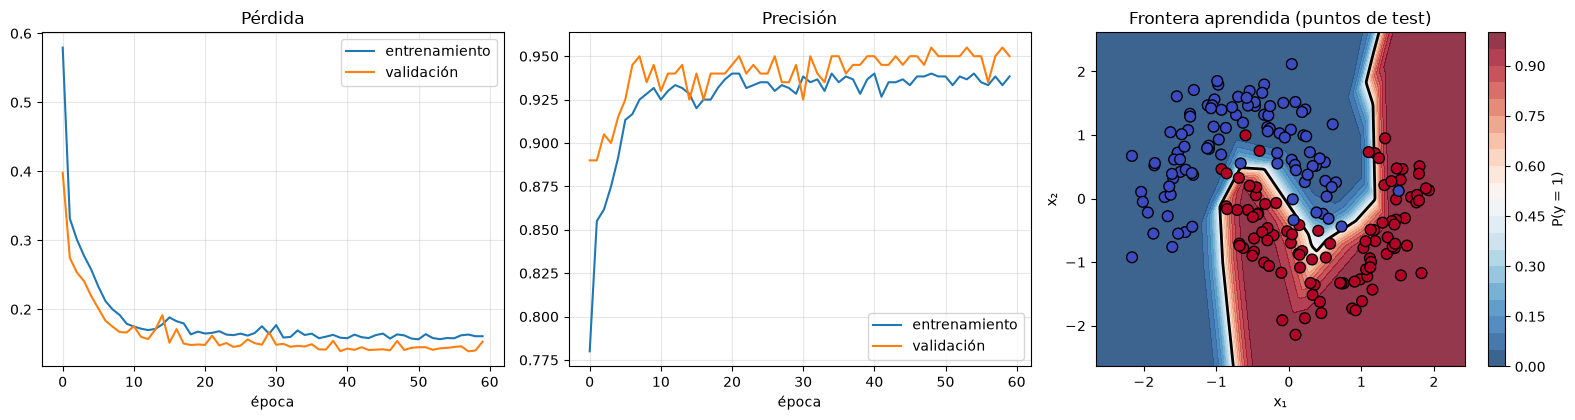

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(hist["tr_loss"], label="entrenamiento"); axes[0].plot(hist["val_loss"], label="validación")
axes[0].set_title("Pérdida"); axes[0].set_xlabel("época"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(hist["tr_acc"], label="entrenamiento"); axes[1].plot(hist["val_acc"], label="validación")
axes[1].set_title("Precisión"); axes[1].set_xlabel("época"); axes[1].legend(); axes[1].grid(alpha=0.3)
cs = frontera_binaria(modelo_lunas, X_te, y_te, axes[2], "Frontera aprendida (puntos de test)")
plt.colorbar(cs, ax=axes[2], label="P(y = 1)"); plt.tight_layout(); plt.show()

---
# Bloque 8 · Clasificación multiclase y evaluación

## 8.1 Tres espirales

Con $C=3$ clases, el modelo devuelve **3 logits** por ejemplo; la pérdida es `CrossEntropyLoss` (§4.4) y la predicción es el `argmax`. Las etiquetas son enteros **`long`** `(m,)`. Este conjunto —tres espirales entrelazadas— es imposible para un modelo lineal y exige profundidad.

In [52]:
def espirales(n=100, K=3, ruido=0.25, seed=0):
    rng = np.random.default_rng(seed)
    X = np.zeros((n * K, 2)); y = np.zeros(n * K, dtype=np.int64)
    for k in range(K):
        r = np.linspace(0.05, 1, n)
        t = np.linspace(k * 4, (k + 1) * 4, n) + rng.normal(0, ruido, n)
        X[k * n:(k + 1) * n] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[k * n:(k + 1) * n] = k
    return X.astype(np.float32), y

X_sp, y_sp = espirales()
perm = np.random.default_rng(1).permutation(len(y_sp)); n_tr = int(0.8 * len(y_sp))
Xs_tr, ys_tr = torch.from_numpy(X_sp[perm[:n_tr]]), torch.from_numpy(y_sp[perm[:n_tr]])
Xs_te, ys_te = torch.from_numpy(X_sp[perm[n_tr:]]), torch.from_numpy(y_sp[perm[n_tr:]])
print("X:", tuple(Xs_tr.shape), Xs_tr.dtype, "| y:", tuple(ys_tr.shape), ys_tr.dtype, "(long, índices de clase)")

torch.manual_seed(0)
net = MLP([2, 64, 64, 3], activation=nn.ReLU)               # 3 logits de salida
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=1e-2)
h = entrenar(net, Xs_tr, ys_tr, criterion, optimizer, epochs=400, imprimir_cada=100)

net.eval()
with torch.no_grad():
    logits_te = net(Xs_te); probs_te = F.softmax(logits_te, dim=1); pred_te = logits_te.argmax(dim=1)
print(f"\nPrecisión en test: {(pred_te == ys_te).float().mean().item():.3f}")
print("Probabilidades de los 3 primeros ejemplos de test (suman 1 por fila):\n", probs_te[:3].numpy().round(3))
print("clases predichas:", pred_te[:3].tolist(), "| reales:", ys_te[:3].tolist())

X: (240, 2) torch.float32 | y: (240,) torch.int64 (long, índices de clase)
Época     1 | pérdida = 1.08323
Época   100 | pérdida = 0.00599
Época   200 | pérdida = 0.00088
Época   300 | pérdida = 0.00033
Época   400 | pérdida = 0.00018

Precisión en test: 1.000
Probabilidades de los 3 primeros ejemplos de test (suman 1 por fila):
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
clases predichas: [0, 1, 2] | reales: [0, 1, 2]


## 8.2 Más allá de la precisión: matriz de confusión, precisión y exhaustividad

La **matriz de confusión** $M$ cuenta cuántos ejemplos de la clase real $i$ se predijeron como $j$. A partir de ella, por clase $k$:

$$\text{precisión}_k=\frac{M_{kk}}{\sum_iM_{ik}}\ \ (\text{de lo que predije }k\text{, ¿cuánto lo era?}),\qquad\text{exhaustividad}_k=\frac{M_{kk}}{\sum_jM_{kj}}\ \ (\text{de lo que era }k\text{, ¿cuánto detecté?})$$

Se calcula con un truco de `bincount` (el índice plano $i\cdot C+j$ identifica la celda):

Matriz de confusión (filas = real, columnas = predicho):
 [[22  0  0]
 [ 0 17  0]
 [ 0  0 21]]
clase 0: precisión 1.000 | exhaustividad 1.000
clase 1: precisión 1.000 | exhaustividad 1.000
clase 2: precisión 1.000 | exhaustividad 1.000

torchmetrics MulticlassAccuracy: 1.0


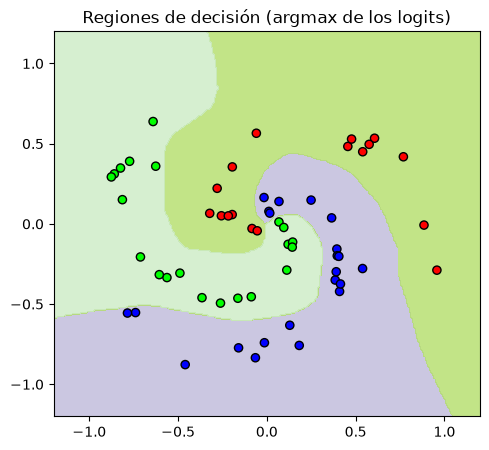

In [53]:
C = 3
M = torch.bincount(ys_te * C + pred_te, minlength=C * C).reshape(C, C)       # filas = real, columnas = predicho
print("Matriz de confusión (filas = real, columnas = predicho):\n", M.numpy())
precision = M.diag() / M.sum(dim=0); exhaustividad = M.diag() / M.sum(dim=1)
for k in range(C):
    print(f"clase {k}: precisión {precision[k].item():.3f} | exhaustividad {exhaustividad[k].item():.3f}")

# Librería de métricas (instalada con Lightning): resultado equivalente
from torchmetrics.classification import MulticlassAccuracy
print("\ntorchmetrics MulticlassAccuracy:", MulticlassAccuracy(num_classes=C)(pred_te, ys_te).item())

# Regiones de decisión
xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
with torch.no_grad():
    region = net(grid).argmax(dim=1).reshape(xx.shape).numpy()
plt.figure(figsize=(5.5, 5))
plt.contourf(xx, yy, region, levels=[-0.5, 0.5, 1.5, 2.5], cmap="Set3", alpha=0.8)
plt.scatter(Xs_te[:, 0], Xs_te[:, 1], c=ys_te, cmap="brg", edgecolors="k", s=35)
plt.title("Regiones de decisión (argmax de los logits)"); plt.show()

## 8.3 `model.train()` frente a `model.eval()`

Algunas capas (**Dropout**, **BatchNorm**; Bloque 9) se comportan **distinto** al entrenar y al evaluar. `model.train()` y `model.eval()` solo cambian ese *interruptor*; **no** desactivan el cálculo de gradientes (eso lo hace `torch.no_grad()`). Receta para evaluar:

```python
model.eval()                 # interruptor de capas (dropout, BN)
with torch.no_grad():        # sin grafo de autograd
    salida = model(x)
model.train()                # no olvides volver a entrenar
```

## 8.4 Resumen de convenciones de salida

| Quiero… | Del modelo salen… | Probabilidad | Clase |
|---|---|---|---|
| binaria | 1 logit $z$ | `torch.sigmoid(z)` | `z > 0` |
| multiclase | $C$ logits | `F.softmax(z, dim=1)` | `z.argmax(dim=1)` |

En ambos casos **las probabilidades solo se calculan al predecir**; al entrenar la pérdida trabaja con logits.

---
# Bloque 9 · Regularización y trucos de entrenamiento

## 9.1 El problema: sobreajuste

Una red grande con pocos datos **memoriza** el entrenamiento (pérdida de entrenamiento $\to0$) pero **generaliza mal** (la pérdida de validación sube). Las herramientas para combatirlo:

| Técnica | Idea | En PyTorch |
|---|---|---|
| **Weight decay** ($L_2$) | penaliza pesos grandes (§5.6, ejercicio 3) | `AdamW(weight_decay=…)` |
| **Dropout** | apaga neuronas al azar al entrenar | `nn.Dropout(p)` |
| **BatchNorm** | normaliza activaciones por lote (estabiliza y regulariza) | `nn.BatchNorm1d` |
| **Early stopping** | parar cuando la validación deja de mejorar | (a mano, abajo) |
| Más datos / *data augmentation* | — | `Dataset` con `transform` |

## 9.2 Dropout

Durante el entrenamiento cada activación se **anula con probabilidad $p$** y las supervivientes se **reescalan por $\tfrac1{1-p}$** (*inverted dropout*), de modo que el valor esperado no cambie:

$$\tilde a_i=\frac{\mu_i\,a_i}{1-p},\qquad\mu_i\sim\text{Bernoulli}(1-p)\ \Longrightarrow\ \mathbb E[\tilde a_i]=a_i$$

En evaluación no se hace nada (identidad). Por eso **`model.eval()` es imprescindible**.

In [54]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
a = torch.ones(1, 10)
drop.train(); print("train:", drop(a))                       # unos cuantos 0 y el resto 2.0 = 1/(1−0.5)
drop.eval();  print("eval :", drop(a))                       # identidad
print("media sobre 100 000 activaciones en train:", F.dropout(torch.ones(100_000), p=0.5, training=True).mean().item(), "(≈ 1: E[ã]=a)")

train: tensor([[0., 0., 2., 0., 0., 0., 2., 2., 0., 2.]])
eval : tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])
media sobre 100 000 activaciones en train: 0.9986000061035156 (≈ 1: E[ã]=a)


## 9.3 Batch Normalization

Normaliza cada característica **sobre el lote** y luego la reescala con dos parámetros **aprendibles** $\gamma,\beta$:

$$\hat x=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\varepsilon}},\qquad y=\gamma\,\hat x+\beta$$

Además guarda **medias y varianzas móviles** (`running_mean`, `running_var`, actualizadas con `momentum=0.1`) que se usan en **evaluación**, cuando no hay un lote del que sacar estadísticas. Es el ejemplo perfecto de por qué importa `train()`/`eval()`. (`LayerNorm`, usada en Transformers, normaliza en cambio **por ejemplo**, sin depender del lote.)

In [55]:
torch.manual_seed(0)
x = torch.randn(32, 4) * 3 + 5                               # lote de 32 ejemplos, media ≈ 5, std ≈ 3
bn = nn.BatchNorm1d(4)

bn.train(); y = bn(x)
print("tras BN (train): media por columna", y.mean(0).detach().numpy().round(4), "| std", y.std(0, unbiased=False).detach().numpy().round(3))
manual = (x - x.mean(0)) / torch.sqrt(x.var(0, unbiased=False) + bn.eps)
print("¿coincide con la fórmula a mano?", torch.allclose(y, manual, atol=1e-5))
print("running_mean tras 1 lote:", bn.running_mean.numpy().round(3), " (= 0.1·media del lote + 0.9·0)")
print("parámetros aprendibles γ, β:", [n for n, _ in bn.named_parameters()], "| buffers:", [n for n, _ in bn.named_buffers()])

bn.eval(); print("\nen eval usa las estadísticas móviles -> media por columna:", bn(x).mean(0).detach().numpy().round(3))
print("LayerNorm (por ejemplo) -> media por FILA:", nn.LayerNorm(4)(x).mean(1)[:4].detach().numpy().round(4))

tras BN (train): media por columna [-0. -0. -0. -0.] | std [1. 1. 1. 1.]
¿coincide con la fórmula a mano? True
running_mean tras 1 lote: [0.44  0.509 0.563 0.551]  (= 0.1·media del lote + 0.9·0)
parámetros aprendibles γ, β: ['weight', 'bias'] | buffers: ['running_mean', 'running_var', 'num_batches_tracked']

en eval usa las estadísticas móviles -> media por columna: [3.007 2.97  3.98  3.716]
LayerNorm (por ejemplo) -> media por FILA: [-0.  0.  0. -0.]


## 9.4 *Early stopping*

Guardamos los pesos del **mejor modelo en validación** y paramos si no mejora durante `paciencia` épocas. Es la regularización más barata que existe. Fíjate en que hay que **copiar** el `state_dict` (`deepcopy`); si no, solo guardaríamos referencias a tensores que siguen cambiando.

In [56]:
import copy

class EarlyStopping:
    def __init__(self, paciencia=30, delta=1e-4):
        self.paciencia, self.delta = paciencia, delta
        self.mejor, self.contador, self.mejor_epoca, self.mejor_estado = float("inf"), 0, 0, None
    def __call__(self, val_loss, modelo, epoca):
        if val_loss < self.mejor - self.delta:              # mejora: guardamos una COPIA de los pesos
            self.mejor, self.contador, self.mejor_epoca = val_loss, 0, epoca
            self.mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            self.contador += 1
        return self.contador >= self.paciencia              # True -> hay que parar

## 9.5 Experimento: sobreajustar a propósito y arreglarlo

Pocos datos (50 de entrenamiento) y una red grande ($2\to128\to128\to1$, ¡17 000 parámetros!) con mucho ruido. Comparamos cinco configuraciones con **la misma semilla de inicialización**. Fíjate en cómo la pérdida de validación de la red base se **dispara** mientras la de entrenamiento sigue bajando.

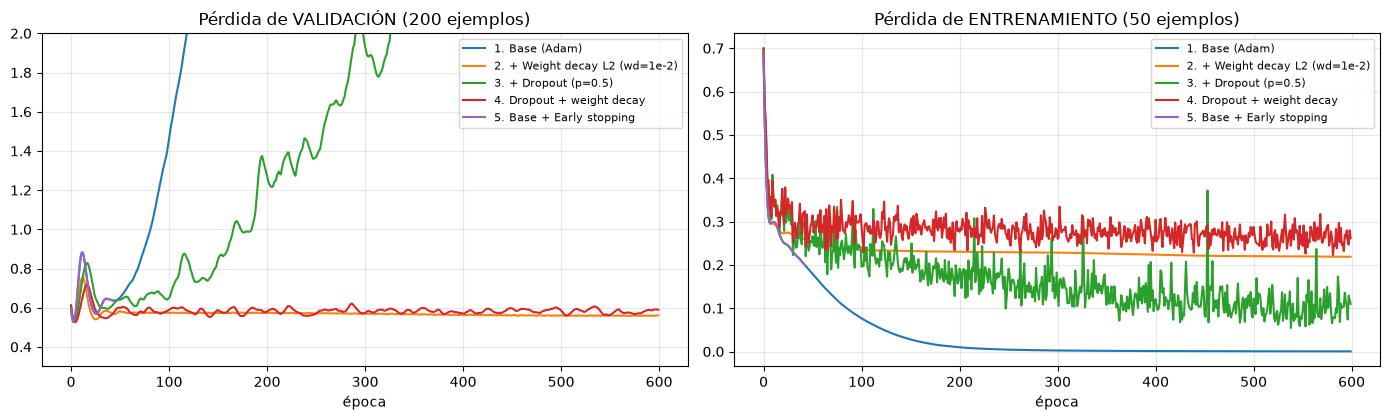

configuración                       épocas   val loss mín. val loss (modelo final)   val acc
1. Base (Adam)                         600          0.5295                  7.7650     0.755
2. + Weight decay L2 (wd=1e-2)         600          0.5286                  0.5607     0.780
3. + Dropout (p=0.5)                   600          0.5292                  3.2879     0.765
4. Dropout + weight decay              600          0.5257                  0.5894     0.770
5. Base + Early stopping                43          0.5295                  0.5295     0.730


In [57]:
X_s, y_s = make_moons(n_samples=250, noise=0.4, random_state=1)
X_s = ((X_s - X_s[:50].mean(0)) / X_s[:50].std(0)).astype(np.float32)             # normalizar con las 50 de train
Xe_tr, ye_tr = torch.from_numpy(X_s[:50]),  torch.from_numpy(y_s[:50].astype(np.float32)).unsqueeze(1)
Xe_va, ye_va = torch.from_numpy(X_s[50:]),  torch.from_numpy(y_s[50:].astype(np.float32)).unsqueeze(1)

def crear(dropout=0.0, bn=False):
    capas, n_in = [], 2
    for _ in range(2):
        capas.append(nn.Linear(n_in, 128)); n_in = 128
        if bn: capas.append(nn.BatchNorm1d(128))
        capas.append(nn.ReLU())
        if dropout > 0: capas.append(nn.Dropout(dropout))
    capas.append(nn.Linear(128, 1))
    return nn.Sequential(*capas)

def experimento(modelo, opt, epochs=600, early=None):
    crit = nn.BCEWithLogitsLoss(); tr, va = [], []
    for epoca in range(1, epochs + 1):
        modelo.train()
        loss = crit(modelo(Xe_tr), ye_tr); opt.zero_grad(); loss.backward(); opt.step()
        modelo.eval()
        with torch.no_grad(): v = crit(modelo(Xe_va), ye_va).item()
        tr.append(loss.item()); va.append(v)
        if early is not None and early(v, modelo, epoca): break
    if early is not None: modelo.load_state_dict(early.mejor_estado)                 # restaurar el mejor modelo
    modelo.eval()
    with torch.no_grad():
        acc = ((modelo(Xe_va) > 0).float() == ye_va).float().mean().item()
        final = crit(modelo(Xe_va), ye_va).item()                                  # pérdida del modelo DEVUELTO
    return {"train": tr, "val": va, "acc": acc, "epocas": len(tr), "final": final}

configs = {
    "1. Base (Adam)":                    (lambda: crear(),             lambda p: torch.optim.Adam(p, lr=5e-3),                      False),
    "2. + Weight decay L2 (wd=1e-2)":    (lambda: crear(),             lambda p: torch.optim.Adam(p, lr=5e-3, weight_decay=1e-2),   False),
    "3. + Dropout (p=0.5)":              (lambda: crear(dropout=0.5),  lambda p: torch.optim.Adam(p, lr=5e-3),                      False),
    "4. Dropout + weight decay":         (lambda: crear(dropout=0.5),  lambda p: torch.optim.Adam(p, lr=5e-3, weight_decay=1e-2),   False),
    "5. Base + Early stopping":          (lambda: crear(),             lambda p: torch.optim.Adam(p, lr=5e-3),                      True),
}
res = {}
for nombre, (mk_m, mk_o, usa_early) in configs.items():
    torch.manual_seed(0)
    m_ = mk_m()
    res[nombre] = experimento(m_, mk_o(m_.parameters()), early=EarlyStopping(paciencia=40) if usa_early else None)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for nombre, r in res.items():
    axes[0].plot(r["val"], label=nombre); axes[1].plot(r["train"], label=nombre)
axes[0].set_title("Pérdida de VALIDACIÓN (200 ejemplos)"); axes[1].set_title("Pérdida de ENTRENAMIENTO (50 ejemplos)")
for ax in axes: ax.set_xlabel("época"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
axes[0].set_ylim(0.3, 2.0); plt.tight_layout(); plt.show()

print(f"{'configuración':<34}{'épocas':>8}{'val loss mín.':>16}{'val loss (modelo final)':>24}{'val acc':>10}")
for nombre, r in res.items():
    print(f"{nombre:<34}{r['epocas']:>8}{min(r['val']):>16.4f}{r['final']:>24.4f}{r['acc']:>10.3f}")

**Lectura de los resultados:**

- La red **base** memoriza las 50 muestras: su pérdida de entrenamiento tiende a 0 mientras la de validación **se multiplica** (la red está "muy segura" de predicciones equivocadas, y la entropía cruzada castiga eso de forma muy dura, §4.3).
- **Weight decay** y **dropout** frenan la memorización; combinados (o con *early stopping*) la pérdida de validación se queda cerca de su mínimo.
- Fíjate en que **pérdida y precisión no mejoran a la vez**: el *early stopping* devuelve el modelo con menor *pérdida*, que no tiene por qué ser el de mayor *precisión*. Elige la métrica de validación que de verdad te importe.

---
# Bloque 10 · Guardar, reproducir y acelerar

## 10.1 Guardar y cargar modelos

**La forma recomendada es guardar solo el `state_dict`** (el diccionario nombre → tensor de los parámetros), no el objeto modelo entero (que depende de cómo esté organizado tu código y usa `pickle`). Para cargarlo, reconstruyes **primero la misma arquitectura** y luego le cargas los pesos.

| Quiero… | Código |
|---|---|
| Guardar pesos | `torch.save(model.state_dict(), "m.pt")` |
| Cargar pesos | `model.load_state_dict(torch.load("m.pt", weights_only=True))` |
| Cargar en CPU un modelo guardado en GPU | `torch.load("m.pt", map_location="cpu")` |
| Reanudar un entrenamiento | guardar también `optimizer.state_dict()`, la época, etc. (*checkpoint*) |

`weights_only=True` es la opción **segura**: impide ejecutar código arbitrario al cargar (el `pickle` normal puede hacerlo; **no cargues archivos `.pt` de fuentes que no conozcas** sin ella).

In [58]:
import os, tempfile

ruta = os.path.join(tempfile.gettempdir(), "modelo_lunas.pt")
torch.save(modelo_lunas.state_dict(), ruta)
print("archivo guardado:", os.path.getsize(ruta), "bytes")

nuevo = MLP([2, 16, 16, 1], activation=nn.ReLU)                       # misma arquitectura, pesos aleatorios
nuevo.load_state_dict(torch.load(ruta, weights_only=True, map_location="cpu"))
nuevo.eval(); modelo_lunas.eval()
x_prueba = torch.from_numpy(X_te[:5])
print("¿mismas predicciones tras cargar?", torch.allclose(modelo_lunas(x_prueba), nuevo(x_prueba)))

# --- Checkpoint completo: modelo + optimizador (+ época...) para REANUDAR el entrenamiento ---
opt_ck = torch.optim.Adam(modelo_lunas.parameters(), lr=1e-2)
modelo_lunas.train()
for xb, yb in loader_tr:                                              # unos pasos para que Adam tenga estado (m, v)
    opt_ck.zero_grad(); nn.BCEWithLogitsLoss()(modelo_lunas(xb), yb).backward(); opt_ck.step(); break
ruta_ck = os.path.join(tempfile.gettempdir(), "checkpoint.pt")
torch.save({"epoca": 61, "modelo": modelo_lunas.state_dict(), "optimizador": opt_ck.state_dict()}, ruta_ck)

ck = torch.load(ruta_ck, weights_only=True)
opt_nuevo = torch.optim.Adam(nuevo.parameters(), lr=1e-2); opt_nuevo.load_state_dict(ck["optimizador"])
print("\nestado de Adam restaurado (momentos m y v por parámetro):", list(opt_nuevo.state_dict()["state"][0].keys()))

archivo guardado: 4497 bytes
¿mismas predicciones tras cargar? True

estado de Adam restaurado (momentos m y v por parámetro): ['step', 'exp_avg', 'exp_avg_sq']


## 10.2 Reproducibilidad

Los resultados varían entre ejecuciones por tres fuentes de azar: la **inicialización** de pesos, el **barajado** de los datos y (en GPU) algunos algoritmos no deterministas. Fija todas las semillas al inicio:

In [59]:
import random

def fijar_semillas(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def entrena_rapido(seed):
    fijar_semillas(seed)
    m = nn.Sequential(nn.Linear(2, 8), nn.Tanh(), nn.Linear(8, 1))
    h = entrenar(m, X_xor, y_xor, nn.BCEWithLogitsLoss(), torch.optim.SGD(m.parameters(), lr=0.5), epochs=100)
    return h[-1]

print("semilla 0:", entrena_rapido(0), "|", entrena_rapido(0), "  <- idénticas")
print("semilla 1:", entrena_rapido(1), "                  <- distinta")

semilla 0: 0.27989643812179565 | 0.27989643812179565   <- idénticas
semilla 1: 0.5462789535522461                   <- distinta


Para **determinismo estricto** en GPU añade `torch.use_deterministic_algorithms(True)` (algunas operaciones serán más lentas o fallarán si no tienen versión determinista). Con `DataLoader`, pasa `generator=torch.Generator().manual_seed(seed)` (como hicimos en §7.4) y, si usas `num_workers>0`, un `worker_init_fn`.

## 10.3 GPU: código agnóstico al dispositivo

El patrón completo (ya lo has usado en `entrenar_loader(..., device=...)`):

```python
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
modelo = modelo.to(device)                       # los PARÁMETROS (se modifica en sitio)
for xb, yb in loader:
    xb, yb = xb.to(device), yb.to(device)        # cada LOTE (devuelve un tensor nuevo: hay que reasignar)
    ...
# Si usas un optimizador, créalo DESPUÉS de mover el modelo a la GPU.
# Para llevar un resultado a NumPy:  t.detach().cpu().numpy()
```

Todos los tensores de una operación deben estar en el **mismo** dispositivo; si no: `RuntimeError: Expected all tensors to be on the same device`.

## 10.4 Precisión mixta y acumulación de gradientes

**Precisión mixta** (`torch.autocast`): las operaciones costosas (matmul, convoluciones) se hacen en `float16`/`bfloat16` (el doble de rápido y la mitad de memoria en GPU moderna) y las sensibles (sumas, pérdidas) en `float32`. En CPU funciona con `bfloat16`:

In [60]:
modelo_lunas.eval()
with torch.no_grad():
    salida_32 = modelo_lunas(x_prueba)
    with torch.autocast(device_type="cpu", dtype=torch.bfloat16):
        salida_16 = modelo_lunas(x_prueba)
print("dtype normal:", salida_32.dtype, "| dentro de autocast:", salida_16.dtype)
print("diferencia máxima:", (salida_32 - salida_16.float()).abs().max().item(), " (pequeña pérdida de precisión)")

dtype normal: torch.float32 | dentro de autocast: torch.bfloat16
diferencia máxima: 0.03055715560913086  (pequeña pérdida de precisión)


En GPU NVIDIA con `float16` se añade un **`GradScaler`** (evita que los gradientes diminutos se redondeen a 0):

```python
scaler = torch.amp.GradScaler("cuda")
with torch.autocast(device_type="cuda", dtype=torch.float16):
    loss = criterion(modelo(xb), yb)
optimizer.zero_grad()
scaler.scale(loss).backward()
scaler.step(optimizer); scaler.update()
```

**Acumulación de gradientes:** ¿tu lote ideal no cabe en memoria? Reparte el lote en $k$ micro-lotes, haz `backward()` de cada uno (los `.grad` **se acumulan**, §2.4) y llama a `step()` una vez. Como el gradiente de la media es la media de gradientes (§4.1), dividir cada pérdida entre $k$ da **exactamente** el gradiente del lote grande:

In [61]:
torch.manual_seed(0)
m1 = nn.Linear(2, 1); m2 = copy.deepcopy(m1)
xb, yb = torch.randn(32, 2), torch.randn(32, 1)

F.mse_loss(m1(xb), yb).backward()                                  # lote grande de 32
for xc, yc in zip(xb.chunk(4), yb.chunk(4)):                       # 4 micro-lotes de 8
    (F.mse_loss(m2(xc), yc) / 4).backward()                        # /k  ← porque J es una MEDIA
print("¿mismo gradiente que el lote grande?", torch.allclose(m1.weight.grad, m2.weight.grad, atol=1e-6))

¿mismo gradiente que el lote grande? True


## 10.5 Otras herramientas del ecosistema PyTorch

| Herramienta | Para qué | Uso mínimo |
|---|---|---|
| `torch.compile(model)` | compila el modelo y acelera (PyTorch ≥ 2) | `modelo = torch.compile(modelo)` |
| `torch.utils.tensorboard` | curvas de entrenamiento interactivas | `SummaryWriter().add_scalar("loss", v, paso)` |
| `torch.profiler` | dónde se va el tiempo y la memoria | `with torch.profiler.profile(): ...` |
| `torch.onnx.export` / `torch.jit.script` | exportar para producción (otros lenguajes/dispositivos) | `torch.onnx.export(modelo, x_ejemplo, "m.onnx")` |
| `torch.set_num_threads(n)` | hilos de CPU | — |
| `torch.backends.cudnn.benchmark=True` | autoajuste de convoluciones con tamaños fijos | — |

**Consejos de rendimiento:** usa `loss.item()` solo para *mostrar*; no guardes tensores con grafo en listas (`hist.append(loss)` conserva el grafo y **llena la memoria**); `no_grad` en evaluación; lotes tan grandes como quepan; `pin_memory=True` + `num_workers>0` si cargar datos es el cuello de botella.

---
# Bloque 11 · Arquitecturas: CNN, secuencias y atención

Todo lo anterior (autograd, pérdidas, optimizadores, bucle) **no cambia**. Solo cambian las *capas* del modelo. Tabla de las más importantes:

| Familia | Capas de `torch.nn` | Entrada típica (`shape`) | Idea |
|---|---|---|---|
| Densa | `Linear` | `(B, n)` | todo conectado con todo |
| **Convolucional** | `Conv1d/2d/3d`, `MaxPool2d`, `AdaptiveAvgPool2d` | imágenes `(B, C, H, W)` | filtros locales con pesos compartidos |
| **Recurrente** | `RNN`, `LSTM`, `GRU` | secuencias `(B, T, n)` con `batch_first=True` | estado oculto que recorre el tiempo |
| Embeddings | `Embedding` | enteros `(B, T)` | tabla de vectores aprendibles |
| **Atención** | `MultiheadAttention`, `TransformerEncoderLayer` | `(B, T, d)` | cada elemento "mira" a los demás |
| Normalización/regularización | `BatchNorm`, `LayerNorm`, `Dropout` | — | Bloque 9 |

## 11.1 Convoluciones

Una capa densa sobre una imagen conecta cada píxel con cada neurona (¡demasiados parámetros, e ignora la vecindad!). Una **convolución** desliza un pequeño filtro $K\times K$ por la imagen, **reutilizando los mismos pesos** en todas las posiciones (*pesos compartidos*) y mirando solo un entorno local:

$$Y_{i,j}=\sum_{u=0}^{K-1}\sum_{v=0}^{K-1}K_{u,v}\;X_{i\cdot S+u,\ j\cdot S+v}+b\qquad\qquad H_{out}=\Bigl\lfloor\frac{H+2P-K}{S}\Bigr\rfloor+1$$

con $S$ = *stride* (paso) y $P$ = *padding* (relleno de ceros). Parámetros de `Conv2d(C_in, C_out, K)`: $C_{out}\,(C_{in}K^2+1)$, **independientes del tamaño de la imagen**.

**Ejemplo a mano:** un detector de bordes verticales sobre una imagen $5\times5$ que pasa de 0 a 1.

In [62]:
img = torch.tensor([[0., 0., 1., 1., 1.]] * 5).reshape(1, 1, 5, 5)           # (N=1, C=1, H=5, W=5): borde vertical
k = torch.tensor([[-1., 0., 1.]] * 3).reshape(1, 1, 3, 3)                     # filtro 'derecha − izquierda'
salida = F.conv2d(img, k)                                                      # (1,1,3,3): sin padding, stride 1

manual = torch.zeros(3, 3)
for i in range(3):
    for j in range(3):
        manual[i, j] = (img[0, 0, i:i + 3, j:j + 3] * k[0, 0]).sum()           # la fórmula, a mano
print("conv2d:\n", salida.squeeze(), "\n¿igual que la fórmula a mano?", torch.allclose(salida.squeeze(), manual))
print("(el filtro 'se enciende' donde hay un cambio de izquierda a derecha)")

print("\nFórmula del tamaño de salida:")
for H, K, P, S in [(8, 3, 1, 1), (8, 3, 0, 1), (8, 3, 1, 2), (28, 5, 0, 1), (28, 5, 2, 2)]:
    real = nn.Conv2d(1, 1, K, stride=S, padding=P)(torch.zeros(1, 1, H, H)).shape[-1]
    print(f"  H={H:>2}, K={K}, P={P}, S={S}:  ⌊({H}+{2*P}-{K})/{S}⌋+1 = {(H + 2 * P - K) // S + 1}  | PyTorch: {real}")

print("\nParámetros para una imagen 8×8 -> 4 mapas de 8×8:")
print("  Linear(64, 4·8·8)       :", sum(p.numel() for p in nn.Linear(64, 256).parameters()))
print("  Conv2d(1, 4, 3, pad=1)  :", sum(p.numel() for p in nn.Conv2d(1, 4, 3, padding=1).parameters()), " (= 4·(1·9+1))")

conv2d:
 tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]]) 
¿igual que la fórmula a mano? True
(el filtro 'se enciende' donde hay un cambio de izquierda a derecha)

Fórmula del tamaño de salida:
  H= 8, K=3, P=1, S=1:  ⌊(8+2-3)/1⌋+1 = 8  | PyTorch: 8
  H= 8, K=3, P=0, S=1:  ⌊(8+0-3)/1⌋+1 = 6  | PyTorch: 6
  H= 8, K=3, P=1, S=2:  ⌊(8+2-3)/2⌋+1 = 4  | PyTorch: 4
  H=28, K=5, P=0, S=1:  ⌊(28+0-5)/1⌋+1 = 24  | PyTorch: 24
  H=28, K=5, P=2, S=2:  ⌊(28+4-5)/2⌋+1 = 14  | PyTorch: 14

Parámetros para una imagen 8×8 -> 4 mapas de 8×8:
  Linear(64, 4·8·8)       : 16640
  Conv2d(1, 4, 3, pad=1)  : 40  (= 4·(1·9+1))


## 11.2 Una CNN completa

Dataset sintético de imágenes $8\times8$: **clase 0 = barra horizontal, clase 1 = barra vertical**, en posición aleatoria y con ruido. Arquitectura típica: *(Conv → ReLU → Pool)* repetido, luego `Flatten` y una capa lineal final. **`MaxPool2d(2)`** se queda con el máximo de cada bloque $2\times2$ y reduce el tamaño a la mitad.

In [63]:
def barras(n, tam=8, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.normal(0, 0.3, size=(n, 1, tam, tam)).astype(np.float32)          # (N, C=1, H, W)
    y = rng.integers(0, 2, size=n)
    for i in range(n):
        p = rng.integers(0, tam)
        if y[i] == 0: X[i, 0, p, :] += 1.0                                      # barra horizontal
        else:         X[i, 0, :, p] += 1.0                                      # barra vertical
    return torch.from_numpy(X), torch.from_numpy(y)

Xi_tr, yi_tr = barras(600, seed=0); Xi_te, yi_te = barras(200, seed=1)
li_tr = DataLoader(TensorDataset(Xi_tr, yi_tr), batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(0))
li_te = DataLoader(TensorDataset(Xi_te, yi_te), batch_size=200)

torch.manual_seed(0)
cnn = nn.Sequential(
    nn.Conv2d(1, 4, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # (1,8,8) -> (4,8,8) -> (4,4,4)
    nn.Conv2d(4, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     #         -> (8,4,4) -> (8,2,2)
    nn.Flatten(),                                                              #         -> 32
    nn.Linear(8 * 2 * 2, 2),                                                   #         -> 2 logits
)

print("Seguimiento de formas (N=1):")
x = Xi_tr[:1]; print(f"  {'entrada':<10} -> {tuple(x.shape)}")
for capa in cnn:
    x = capa(x); print(f"  {capa.__class__.__name__:<10} -> {tuple(x.shape)}")
print("\nParámetros CNN:", sum(p.numel() for p in cnn.parameters()), "(= 40 + 296 + 66)")
print("Parámetros de un MLP 64→32→2 equivalente en tamaño de entrada:", sum(p.numel() for p in nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 2)).parameters()))

hist_cnn = entrenar_loader(cnn, li_tr, li_te, nn.CrossEntropyLoss(), torch.optim.Adam(cnn.parameters(), lr=1e-2), epochs=12)
print(f"\nPrecisión en test: {evaluar(cnn, li_te, nn.CrossEntropyLoss())[1]:.3f}")

Seguimiento de formas (N=1):
  entrada    -> (1, 1, 8, 8)
  Conv2d     -> (1, 4, 8, 8)
  ReLU       -> (1, 4, 8, 8)
  MaxPool2d  -> (1, 4, 4, 4)
  Conv2d     -> (1, 8, 4, 4)
  ReLU       -> (1, 8, 4, 4)
  MaxPool2d  -> (1, 8, 2, 2)
  Flatten    -> (1, 32)
  Linear     -> (1, 2)

Parámetros CNN: 402 (= 40 + 296 + 66)
Parámetros de un MLP 64→32→2 equivalente en tamaño de entrada: 2146
Época   1 | train: pérdida 0.5640 acc 0.767 | val: pérdida 0.3072 acc 0.970
Época   2 | train: pérdida 0.1268 acc 0.977 | val: pérdida 0.0225 acc 1.000
Época   4 | train: pérdida 0.0064 acc 1.000 | val: pérdida 0.0183 acc 0.990
Época   6 | train: pérdida 0.0028 acc 1.000 | val: pérdida 0.0022 acc 1.000
Época   8 | train: pérdida 0.0011 acc 1.000 | val: pérdida 0.0019 acc 1.000
Época  10 | train: pérdida 0.0008 acc 1.000 | val: pérdida 0.0016 acc 1.000
Época  12 | train: pérdida 0.0006 acc 1.000 | val: pérdida 0.0014 acc 1.000

Precisión en test: 1.000


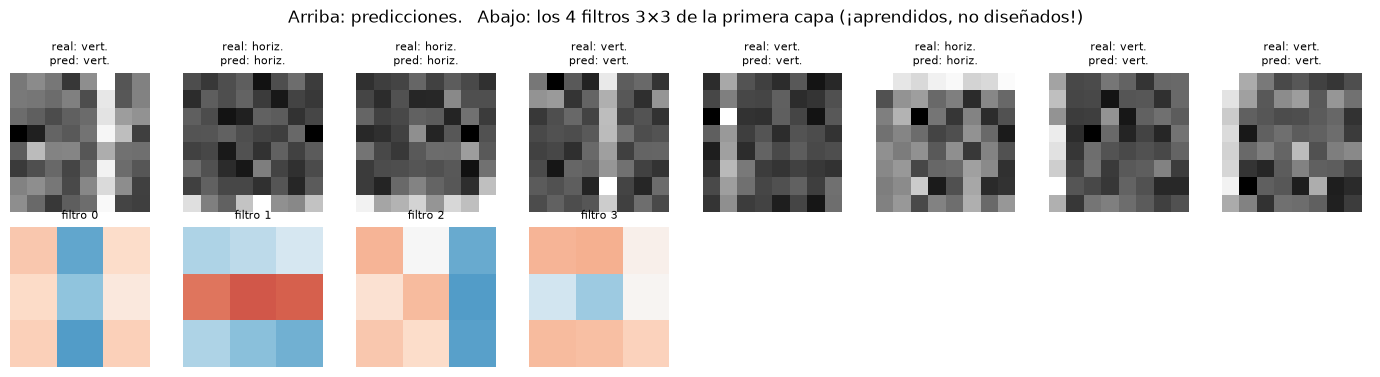

In [64]:
cnn.eval()
with torch.no_grad():
    pred = cnn(Xi_te[:8]).argmax(dim=1)
nombres = ["horiz.", "vert."]

fig, axes = plt.subplots(2, 8, figsize=(14, 3.8))
for i in range(8):
    axes[0, i].imshow(Xi_te[i, 0], cmap="gray"); axes[0, i].axis("off")
    axes[0, i].set_title(f"real: {nombres[yi_te[i]]}\npred: {nombres[pred[i]]}", fontsize=8)
filtros = cnn[0].weight.detach()                                               # (4, 1, 3, 3): 4 filtros aprendidos
for i in range(4):
    axes[1, i].imshow(filtros[i, 0], cmap="RdBu", vmin=-1, vmax=1); axes[1, i].axis("off"); axes[1, i].set_title(f"filtro {i}", fontsize=8)
for i in range(4, 8): axes[1, i].axis("off")
plt.suptitle("Arriba: predicciones.   Abajo: los 4 filtros 3×3 de la primera capa (¡aprendidos, no diseñados!)"); plt.tight_layout(); plt.show()

## 11.3 Secuencias: `Embedding` y `LSTM`

Para datos **ordenados** (texto, series temporales) las redes recurrentes procesan un elemento cada vez y arrastran un **estado oculto** $h_t$ que resume el pasado. La `LSTM` añade una "memoria" de celda controlada por *puertas* para poder recordar a largo plazo (evita el gradiente que se desvanece de §5.3.8 a lo largo del tiempo).

**Formas** (con `batch_first=True`): entrada `(B, T, n_in)`; salida por instante `(B, T, H)`; último estado oculto `h_n` `(num_capas, B, H)`.

**Embeddings:** para texto, cada palabra es un entero (índice) que `nn.Embedding` convierte en un vector aprendible. Es exactamente una **tabla de búsqueda**, equivalente a multiplicar un *one-hot* por la matriz de pesos:

In [65]:
emb = nn.Embedding(num_embeddings=10, embedding_dim=4)           # vocabulario de 10 palabras -> vectores de 4
ids = torch.tensor([[1, 2, 3], [4, 5, 6]])                        # (B=2, T=3): enteros LONG
print("Embedding:", tuple(ids.shape), "->", tuple(emb(ids).shape))
print("¿embedding == one_hot @ W?", torch.allclose(emb(ids), F.one_hot(ids, 10).float() @ emb.weight))

lstm = nn.LSTM(input_size=3, hidden_size=5, batch_first=True)
x = torch.randn(4, 10, 3)                                         # (B=4, T=10, n_in=3)
out, (h_n, c_n) = lstm(x)
print("\nLSTM: entrada", tuple(x.shape), "-> out", tuple(out.shape), "| h_n", tuple(h_n.shape), "| c_n", tuple(c_n.shape))
print("¿el último instante de 'out' es h_n?", torch.allclose(out[:, -1], h_n[-1]))

Embedding: (2, 3) -> (2, 3, 4)
¿embedding == one_hot @ W? True

LSTM: entrada (4, 10, 3) -> out (4, 10, 5) | h_n (1, 4, 5) | c_n (1, 4, 5)
¿el último instante de 'out' es h_n? True


**Tarea de memoria:** secuencias de $T=12$ números aleatorios; la etiqueta es **el signo del primer elemento**. Para acertar, la red debe *recordar* el primer valor durante 11 pasos de ruido.

In [66]:
def secuencias(n, T=12, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, T, 1)).astype(np.float32)
    y = (X[:, 0, 0] > 0).astype(np.int64)                         # depende SOLO del primer elemento
    return torch.from_numpy(X), torch.from_numpy(y)

class ClasificadorLSTM(nn.Module):
    def __init__(self, n_in=1, hidden=16, n_clases=2):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, n_clases)
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)                                # h_n: (1, B, H)
        return self.fc(h_n[-1])                                   # logits (B, 2) a partir del último estado oculto

Xq_tr, yq_tr = secuencias(800, seed=0); Xq_te, yq_te = secuencias(200, seed=1)
lq_tr = DataLoader(TensorDataset(Xq_tr, yq_tr), batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(0))
lq_te = DataLoader(TensorDataset(Xq_te, yq_te), batch_size=200)

torch.manual_seed(0)
lstm_clf = ClasificadorLSTM()
hist_lstm = entrenar_loader(lstm_clf, lq_tr, lq_te, nn.CrossEntropyLoss(), torch.optim.Adam(lstm_clf.parameters(), lr=1e-2), epochs=60)
print(f"\nPrecisión en test: {evaluar(lstm_clf, lq_te, nn.CrossEntropyLoss())[1]:.3f}   (azar = 0.5)")

Época   1 | train: pérdida 0.6979 acc 0.479 | val: pérdida 0.6933 acc 0.510
Época  10 | train: pérdida 0.6934 acc 0.506 | val: pérdida 0.6934 acc 0.510
Época  20 | train: pérdida 0.6927 acc 0.509 | val: pérdida 0.6940 acc 0.520
Época  30 | train: pérdida 0.6981 acc 0.504 | val: pérdida 0.6968 acc 0.490
Época  40 | train: pérdida 0.6941 acc 0.482 | val: pérdida 0.6938 acc 0.485
Época  50 | train: pérdida 0.6936 acc 0.490 | val: pérdida 0.6938 acc 0.450
Época  60 | train: pérdida 0.6931 acc 0.509 | val: pérdida 0.6941 acc 0.500

Precisión en test: 0.500   (azar = 0.5)


Fíjate en la **meseta**: durante muchas épocas la red se queda en el azar (pérdida $\approx\ln2=0.693$) y de pronto "encuentra" cómo usar la memoria y la pérdida se desploma. Es típico de las tareas de memoria a largo plazo; los gradientes que llegan al primer elemento son diminutos (§5.3.8) hasta que la LSTM ajusta sus puertas lo justo. Prueba a aumentar $T$ y verás que la meseta se alarga.

## 11.4 Atención y Transformers

La **atención** permite que cada elemento de una secuencia "consulte" a todos los demás y se quede con una mezcla ponderada de sus valores. Con consultas $Q$, claves $K$ y valores $V$ (cada uno `(B, T, d)`):

$$\operatorname{Atención}(Q,K,V)=\operatorname{softmax}\!\Bigl(\frac{QK^{T}}{\sqrt{d}}\Bigr)V$$

El factor $1/\sqrt d$ evita que los productos escalares crezcan con $d$ y saturen la softmax (¡el mismo problema de gradientes que vimos con la sigmoide!). La atención es **solo producto de matrices y softmax**: los mismos ingredientes de tus apuntes.

In [67]:
torch.manual_seed(0)
B, T, d = 2, 5, 8
Q, K, V = (torch.randn(B, T, d) for _ in range(3))

scores = Q @ K.transpose(-2, -1) / d ** 0.5            # (B,T,T): cuánto se "parece" cada par de posiciones
att = scores.softmax(dim=-1)                           # cada FILA suma 1
mia = att @ V                                          # mezcla ponderada de los valores  (B,T,d)
ref = F.scaled_dot_product_attention(Q, K, V)          # versión optimizada de PyTorch
print("¿mi atención == F.scaled_dot_product_attention?", torch.allclose(mia, ref, atol=1e-6))
print("suma de cada fila de pesos de atención:", att[0].sum(-1).numpy().round(3))

# Máscara causal (modelos de lenguaje): la posición 0 solo puede mirarse a sí misma
causal = F.scaled_dot_product_attention(Q, K, V, is_causal=True)
print("¿con máscara causal, la salida 0 es exactamente V[0]?", torch.allclose(causal[:, 0], V[:, 0], atol=1e-6))

# Bloque Transformer completo ya hecho: atención multi-cabeza + red densa + normalización + residuales
bloque = nn.TransformerEncoderLayer(d_model=16, nhead=4, dim_feedforward=32, batch_first=True)
x = torch.randn(2, 10, 16)
print("\nTransformerEncoderLayer:", tuple(x.shape), "->", tuple(bloque(x).shape), "| parámetros:", sum(p.numel() for p in bloque.parameters()))

¿mi atención == F.scaled_dot_product_attention? True
suma de cada fila de pesos de atención: [1. 1. 1. 1. 1.]
¿con máscara causal, la salida 0 es exactamente V[0]? True

TransformerEncoderLayer: (2, 10, 16) -> (2, 10, 16) | parámetros: 2224


---
# Bloque 12 · Otras librerías para redes neuronales

PyTorch no es la única opción. Todas las librerías implementan **las mismas ideas** que ya conoces (capas, pérdida, gradiente, optimizador); cambian el **estilo** y el **nivel de abstracción**:

| Librería | Filosofía | Mejor para | ¿Autograd? |
|---|---|---|---|
| **scikit-learn** (`MLPClassifier`) | API `fit/predict`, todo preconfigurado | *baselines* rápidos con datos tabulares | interno |
| **PyTorch** | imperativa y flexible (la de este cuaderno) | **investigación y producción general** | `backward()` |
| **Keras** (TensorFlow, y desde Keras 3 también JAX/PyTorch) | alto nivel: `compile()` + `fit()` | prototipar rápido, producción en el ecosistema TF | integrado |
| **JAX** (+ Optax, Flax) | **funcional**: funciones puras + transformaciones (`grad`, `jit`, `vmap`) | investigación, cálculo científico, TPU | `jax.grad` |
| **PyTorch Lightning** | "organiza" PyTorch: tú escribes el modelo, él el bucle | proyectos serios con PyTorch, multi-GPU | el de PyTorch |
| **Hugging Face** (`transformers`) | modelos **preentrenados** listos | NLP, visión y audio con modelos grandes | el de PyTorch/TF/JAX |

Compararemos todas en **el mismo problema** (las dos lunas del Bloque 7, mismos datos y misma partición); cada celda anota su precisión de test en el diccionario `resultados` que empezamos en §7.5.

## 12.1 scikit-learn: `MLPClassifier`

La opción más cómoda cuando solo quieres un perceptrón multicapa estándar: **un objeto, `fit` y `predict`**. Mapa de conceptos con tus apuntes:

| Parámetro de `MLPClassifier` | Equivale a |
|---|---|
| `hidden_layer_sizes=(16, 16)` | `layer_sizes = [n0, 16, 16, n_L]` (n0 y n_L se infieren de los datos) |
| `activation="relu"` | activación de las capas ocultas (la salida es sigmoide/softmax automáticamente) |
| `solver="adam"` / `"sgd"` | optimizador |
| `learning_rate_init` | $\alpha$ |
| `alpha=1e-4` | **regularización $L_2$**: suma $\frac{\alpha}{2m}\sum\lVert W\rVert^2$ (¡la misma de §4.1!) |
| `batch_size`, `max_iter` | tamaño de mini-lote y nº de épocas |
| `early_stopping=True` | para cuando la validación no mejora |

Limitaciones: solo MLP densos, **sin GPU**, sin pérdidas ni arquitecturas personalizadas. Detalle de convención: guarda los pesos como `coefs_[l]` con forma $(n^{[l-1]},\,n^{[l]})$, es decir, **$W^T$** (¡otra convención más!).

In [68]:
from sklearn.neural_network import MLPClassifier
import warnings

import time; t0 = time.time()
clf = MLPClassifier(hidden_layer_sizes=(16, 16), activation="relu", solver="adam", learning_rate_init=1e-2,
                    alpha=1e-4, batch_size=32, max_iter=60, random_state=0)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")                         # ConvergenceWarning: llegó a max_iter
    clf.fit(X_tr, y_tr.astype(int))
acc_sk = clf.score(X_te, y_te.astype(int))
print(f"scikit-learn MLPClassifier | precisión en test: {acc_sk:.3f} | tiempo: {time.time() - t0:.1f}s")
print("formas de coefs_:", [c.shape for c in clf.coefs_], "-> (n_in, n_out) = Wᵀ  (en PyTorch: weight (n_out, n_in))")
print("nº de épocas ejecutadas:", clf.n_iter_, "| última pérdida de entrenamiento:", round(clf.loss_curve_[-1], 4))
print("predict_proba (3 primeros):\n", clf.predict_proba(X_te[:3]).round(3))
resultados["scikit-learn (MLPClassifier)"] = acc_sk

scikit-learn MLPClassifier | precisión en test: 0.940 | tiempo: 0.2s
formas de coefs_: [(2, 16), (16, 16), (16, 1)] -> (n_in, n_out) = Wᵀ  (en PyTorch: weight (n_out, n_in))
nº de épocas ejecutadas: 38 | última pérdida de entrenamiento: 0.1681
predict_proba (3 primeros):
 [[0.995 0.005]
 [0.002 0.998]
 [0.996 0.004]]


## 12.2 Keras (TensorFlow)

**Keras** es la API de alto nivel de TensorFlow. Su idea: describes el modelo, lo **`compile`** (eliges optimizador y pérdida) y llamas a **`fit`**, que ejecuta *por ti* todo el bucle de mini-lotes, épocas y validación. Mapa con PyTorch:

| Keras | PyTorch (este cuaderno) |
|---|---|
| `keras.Sequential([...])`, `layers.Dense(n)` | `nn.Sequential(...)`, `nn.Linear` |
| `model.compile(optimizer, loss, metrics)` | elegir `criterion` y `optimizer` |
| `model.fit(X, y, batch_size, epochs, validation_data)` | el bucle de §7.5 (`entrenar_loader`) |
| `callbacks=[EarlyStopping(...)]` | nuestra clase `EarlyStopping` (§9.4) |
| `model.evaluate`, `model.predict` | `evaluar(...)`, `modelo(x)` |
| `model.summary()` | `print(modelo)` + contar parámetros |

Notas: (1) Keras usa también **ejemplos en filas** `(m, n)`. (2) **Keras 3 es multi-*backend***: el mismo código corre sobre TensorFlow, JAX o PyTorch eligiendo `os.environ["KERAS_BACKEND"]` *antes* de importarlo. (3) Con `from_logits=True` (como hacemos con PyTorch) la métrica de exactitud binaria debe usar `threshold=0.0`, porque compara **logits**, no probabilidades.

In [69]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")             # silencia los avisos de TensorFlow (opcional)
import keras

keras.utils.set_random_seed(0)
modelo_k = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1),                                        # logit (sin activación), como en PyTorch
])
modelo_k.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-2),
                 loss=keras.losses.BinaryCrossentropy(from_logits=True),       # ≈ nn.BCEWithLogitsLoss
                 metrics=[keras.metrics.BinaryAccuracy(threshold=0.0, name="acc")])
modelo_k.summary()

hist_k = modelo_k.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=60, batch_size=32, verbose=0,
                      callbacks=[keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)])
loss_k, acc_k = modelo_k.evaluate(X_te, y_te, verbose=0)
print(f"\nKeras ({keras.backend.backend()}) | épocas ejecutadas: {len(hist_k.history['loss'])} | test: pérdida {loss_k:.4f}, precisión {acc_k:.3f}")
resultados[f"Keras ({keras.backend.backend()})"] = acc_k

ModuleNotFoundError: No module named 'keras'

## 12.3 JAX (+ Optax y Flax)

**JAX** es NumPy con superpoderes, basado en un paradigma **funcional**: no hay objetos con estado oculto, sino **funciones puras** a las que aplicas *transformaciones*:

| Transformación | Qué hace |
|---|---|
| `jax.grad(f)` | devuelve la función que calcula $\nabla f$ (respecto del 1.er argumento) |
| `jax.jit(f)` | compila `f` con XLA (muy rápido en CPU/GPU/TPU) |
| `jax.vmap(f)` | vectoriza `f` sobre un eje de lotes **sin escribir bucles** |

Los parámetros son un **árbol** (*pytree*: dicts/listas de arrays) que **pasas explícitamente** a las funciones, y un paso de entrenamiento *devuelve* los parámetros nuevos (no se modifican en sitio). **Optax** aporta optimizadores (`optax.adam`…) y pérdidas; **Flax** aporta capas con sintaxis cercana a PyTorch.

**Primero, tu §5.4 otra vez:** una sola línea, `jax.grad`, da los gradientes de la red $2\to2\to1$.

In [ ]:
import jax, jax.numpy as jnp, optax

params_a = {"W1": jnp.array([[0.2, -0.3], [0.4, 0.1]]), "b1": jnp.array([[0.1], [-0.1]]),
            "W2": jnp.array([[0.3, -0.2]]),             "b2": jnp.array([[0.05]])}
x_a, y_a = jnp.array([[1.0], [0.5]]), jnp.array([[1.0]])

def loss_apuntes(p, x, y):                                       # SOLO el forward + la pérdida (convención de columnas)
    a1 = jax.nn.sigmoid(p["W1"] @ x + p["b1"]); a2 = jax.nn.sigmoid(p["W2"] @ a1 + p["b2"])
    return 0.5 * jnp.sum((a2 - y) ** 2)

grads = jax.grad(loss_apuntes)(params_a, x_a, y_a)                # ← la retropropagación entera
print("dW2 =", np.asarray(grads["W2"]).ravel().round(5), "| apuntes §5.4: [-0.06389 -0.06973]")
print("db2 =", np.asarray(grads["b2"]).ravel().round(5), "| apuntes §5.4: [-0.11887]")
print("dW1 =\n", np.asarray(grads["W1"]).round(5))

**Entrenamiento completo con `jit` y Optax.** Los parámetros son una lista de diccionarios con $W^{[l]}$ de forma $(n^{[l]},n^{[l-1]})$, como en tus apuntes. Fíjate en el estilo funcional: `paso(params, opt_state, x, y)` **devuelve** `params` y `opt_state` nuevos.

In [ ]:
def init_params(key, sizes):
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)                          # en JAX el azar es EXPLÍCITO (claves), no un estado global
        params.append({"W": jax.random.normal(sub, (n_out, n_in)) * jnp.sqrt(2.0 / n_in),   # He, forma (n_out, n_in)
                       "b": jnp.zeros(n_out)})
    return params

def forward(params, x):                                           # x: (m, n_in)  -> logits (m,)
    for p in params[:-1]:
        x = jax.nn.relu(x @ p["W"].T + p["b"])
    p = params[-1]
    return (x @ p["W"].T + p["b"]).squeeze(-1)

def loss_fn(params, x, y):
    return optax.sigmoid_binary_cross_entropy(forward(params, x), y).mean()      # J (media)

opt = optax.adam(1e-2)
params = init_params(jax.random.PRNGKey(0), [2, 16, 16, 1])
opt_state = opt.init(params)

@jax.jit                                                          # compila el paso completo
def paso(params, opt_state, x, y):
    loss, grads = jax.value_and_grad(loss_fn)(params, x, y)
    updates, opt_state = opt.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, loss

rng = np.random.default_rng(0)
t0 = time.time()
for epoca in range(60):
    perm = rng.permutation(len(X_tr))                             # barajar en cada época
    for i in range(0, len(perm), 32):
        idx = perm[i:i + 32]
        params, opt_state, loss = paso(params, opt_state, X_tr[idx], y_tr[idx])
acc_jax = float(((forward(params, X_te) > 0) == y_te).mean())
print(f"JAX + Optax | precisión en test: {acc_jax:.3f} | última pérdida de lote: {float(loss):.4f} | tiempo: {time.time() - t0:.1f}s")
resultados["JAX (jit + Optax)"] = acc_jax

**El superpoder `vmap`: un gradiente *por ejemplo*.** En §4.1 vimos que $\nabla J$ es la **media** de los gradientes por ejemplo $\nabla\mathcal L^{(i)}$. En PyTorch obtener cada $\nabla\mathcal L^{(i)}$ por separado exige bucles; en JAX, `vmap(grad(...))` lo vectoriza. Y verificamos la regla de §4.1:

In [ ]:
def loss_un_ejemplo(params, x, y):                                # ℒ de UN ejemplo (escalar)
    return optax.sigmoid_binary_cross_entropy(forward(params, x[None]), y[None]).squeeze()

grads_i = jax.vmap(jax.grad(loss_un_ejemplo), in_axes=(None, 0, 0))(params, X_te[:8], y_te[:8])   # un gradiente POR ejemplo
grad_J = jax.grad(loss_fn)(params, X_te[:8], y_te[:8])                                            # gradiente de J

print("forma del gradiente de W¹ por ejemplo:", grads_i[0]["W"].shape, "= (m=8, n¹, n⁰)")
print("¿∇J == media de los ∇ℒ⁽ⁱ⁾ ?  (la regla de §4.1)", bool(np.allclose(grads_i[0]["W"].mean(axis=0), grad_J[0]["W"], atol=1e-6)))

**Flax NNX:** capas con estado, estilo parecido a PyTorch, sobre JAX. Un paso de entrenamiento queda así de compacto:

In [ ]:
from flax import nnx

class MLPFlax(nnx.Module):
    def __init__(self, rngs):
        self.l1 = nnx.Linear(2, 16, rngs=rngs)
        self.l2 = nnx.Linear(16, 16, rngs=rngs)
        self.l3 = nnx.Linear(16, 1, rngs=rngs)
    def __call__(self, x):
        return self.l3(nnx.relu(self.l2(nnx.relu(self.l1(x))))).squeeze(-1)

modelo_f = MLPFlax(nnx.Rngs(0))
opt_f = nnx.Optimizer(modelo_f, optax.adam(1e-2), wrt=nnx.Param)

@nnx.jit
def paso_flax(modelo, opt, x, y):
    def perdida(m): return optax.sigmoid_binary_cross_entropy(m(x), y).mean()
    loss, grads = nnx.value_and_grad(perdida)(modelo)
    opt.update(modelo, grads)
    return loss

for epoca in range(60):
    perm = rng.permutation(len(X_tr))
    for i in range(0, len(perm), 32):
        idx = perm[i:i + 32]
        loss = paso_flax(modelo_f, opt_f, X_tr[idx], y_tr[idx])
acc_flax = float(((modelo_f(X_te) > 0) == y_te).mean())
print(f"Flax NNX | precisión en test: {acc_flax:.3f}")
resultados["Flax NNX"] = acc_flax

## 12.4 PyTorch Lightning

**Lightning** no es otro framework: es una **capa de organización sobre PyTorch**. Tú escribes lo *específico* (modelo, `training_step`, optimizador) y él se encarga del *boilerplate*: el bucle, `train()/eval()`, `no_grad`, GPU/multi-GPU, *checkpoints*, *logging*, precisión mixta. Mapa:

| Lightning | Tu bucle de PyTorch |
|---|---|
| `LightningModule.training_step(batch, i)` | cuerpo del bucle: forward + pérdida (devuelve `loss`) |
| `configure_optimizers()` | creación del optimizador (y *scheduler*) |
| `validation_step`, `test_step` | `evaluar(...)` |
| `self.log("nombre", valor)` | acumular y mostrar métricas |
| `Trainer(max_epochs, accelerator)` + `trainer.fit(...)` | el doble `for` completo, `zero_grad`, `backward`, `step`, `.to(device)`… |

Observa que **no hay** `zero_grad()`, `backward()` ni `step()`: los hace el `Trainer`.

In [ ]:
import lightning as L
import logging
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)  # silencia el log informativo de Lightning (opcional)
warnings.filterwarnings("ignore", module="lightning")

class LitMLP(L.LightningModule):
    def __init__(self, lr=1e-2):
        super().__init__()
        self.save_hyperparameters()
        self.red = MLP([2, 16, 16, 1], activation=nn.ReLU)           # reutilizamos nuestro MLP
        self.crit = nn.BCEWithLogitsLoss()
    def forward(self, x):
        return self.red(x)
    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.crit(self(x), y)
        self.log("train_loss", loss)
        return loss                                                  # ← Lightning hace zero_grad / backward / step
    def validation_step(self, batch, batch_idx):
        x, y = batch; salida = self(x)
        self.log("val_loss", self.crit(salida, y)); self.log("val_acc", ((salida > 0).float() == y).float().mean())
    def test_step(self, batch, batch_idx):
        x, y = batch
        self.log("test_acc", ((self(x) > 0).float() == y).float().mean())
    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

L.seed_everything(0, verbose=False)
lit = LitMLP()
trainer = L.Trainer(max_epochs=60, accelerator="auto", logger=False, enable_checkpointing=False,
                    enable_progress_bar=False, enable_model_summary=False)
trainer.fit(lit, loader_tr, loader_val)
acc_lit = trainer.test(lit, loader_te, verbose=False)[0]["test_acc"]
print(f"\nPyTorch Lightning | precisión en test: {acc_lit:.3f}")
resultados["PyTorch Lightning"] = acc_lit

## 12.5 Hugging Face y *transfer learning* (modelos preentrenados)

En la práctica **rara vez se entrena desde cero**: se parte de un modelo **preentrenado** en un conjunto enorme y se **afina** (*fine-tuning*) con pocos datos. Ya tienes todos los conceptos (`requires_grad_(False)` para congelar, §3.6; *learning rate* pequeño, §5.6). Estas celdas **no se ejecutan aquí** porque descargan modelos de Internet, pero funcionan en tu equipo:

**Visión con `torchvision` — congelar el cuerpo y entrenar solo una cabeza nueva:**

```python
from torchvision import models
modelo = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)   # preentrenado en ImageNet
for p in modelo.parameters():
    p.requires_grad_(False)                                         # congelamos todo...
modelo.fc = nn.Linear(modelo.fc.in_features, 3)                     # ...salvo una capa final nueva (3 clases)
optimizer = torch.optim.Adam(modelo.fc.parameters(), lr=1e-3)       # solo se optimiza la cabeza
# a partir de aquí: exactamente el mismo bucle de entrenamiento de §7.5
```

**Lenguaje con `transformers` — un modelo listo para usar en 2 líneas:**

```python
from transformers import pipeline
clasificador = pipeline("sentiment-analysis")                       # descarga un modelo ya entrenado
print(clasificador("Este cuaderno de PyTorch es muy claro"))
```

**…y afinado con tus propios datos:**

```python
from transformers import AutoTokenizer, AutoModelForSequenceClassification
tokenizador = AutoTokenizer.from_pretrained("bert-base-uncased")
modelo = AutoModelForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)   # es un nn.Module de PyTorch
# se entrena con tu bucle, con Lightning, o con la clase Trainer de la propia librería
```

El resto del ecosistema, de un vistazo:

| Herramienta | Para qué |
|---|---|
| `torchvision`, `torchaudio` | datasets, transformaciones y modelos de visión / audio |
| `timm` | cientos de modelos de visión preentrenados |
| `transformers`, `datasets`, `peft` | modelos de lenguaje/visión, carga de datos, ajuste eficiente (LoRA) |
| `torchmetrics` | métricas listas (usada en §8.2) |
| `skorch` | envuelve un modelo de PyTorch con la API `fit/predict` de scikit-learn |
| `optuna` | búsqueda automática de hiperparámetros |
| TensorBoard, Weights & Biases, MLflow | seguimiento de experimentos |
| ONNX Runtime | ejecutar modelos exportados en producción |

## 12.6 Resultados y cómo elegir

In [ ]:
print(f"Mismo problema (dos lunas), mismos datos y misma partición — precisión en TEST:\n")
for nombre, acc in sorted(resultados.items(), key=lambda kv: -kv[1]):
    print(f"  {nombre:<36} {acc:.3f}  {'█' * int(acc * 40)}")
print("\nTodas rondan lo mismo: el problema, el modelo y el optimizador son iguales; lo que cambia es la ergonomía, no las matemáticas.")

**Guía de decisión rápida:**

| Si… | Usa |
|---|---|
| Datos tabulares y quieres un *baseline* en 3 líneas | **scikit-learn** |
| Quieres aprender, investigar o máxima flexibilidad | **PyTorch** (+ **Lightning** cuando el proyecto crezca) |
| Quieres prototipar con la menor cantidad de código | **Keras** |
| Necesitas rendimiento extremo, TPU, o transformaciones como `vmap`/`jit` | **JAX** (+ Flax/Optax) |
| Quieres partir de un modelo grande preentrenado | **Hugging Face** + PyTorch |

Y una buena noticia: lo que has aprendido (tensores, autograd, `nn`, pérdidas, optimizadores, bucle, regularización) **se transfiere casi 1 a 1** entre todas ellas.

---
# Bloque 13 · Errores típicos, chuleta y ejercicios

## 13.1 Los errores que todos cometemos

Cuatro de ellos, **provocados a propósito** para que reconozcas el síntoma:

In [ ]:
# ---- Error 1: olvidar optimizer.zero_grad() (minimizamos f(w) = w², con w₀ = 5) ----
def prueba(con_zero_grad, pasos=30):
    w = torch.tensor([5.0], requires_grad=True); opt = torch.optim.SGD([w], lr=0.1); tray = []
    for _ in range(pasos):
        if con_zero_grad: opt.zero_grad()
        (w ** 2).sum().backward(); opt.step(); tray.append(w.item())
    return tray
con, sin = prueba(True), prueba(False)
print("1) CON zero_grad:", np.round(con[:4], 3), "...", f"w final = {con[-1]:.4f}  (converge a 0)")
print("   SIN zero_grad:", np.round(sin[:6], 2), "...", f"|w| máx. en los últimos 10 pasos = {max(abs(v) for v in sin[-10:]):.2f}  (¡oscila sin converger!)")

# ---- Error 2: olvidar model.eval() con Dropout ----
torch.manual_seed(0)
con_dropout = nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Dropout(0.5), nn.Linear(32, 1))
x1 = torch.randn(1, 2)
con_dropout.train(); a, b = con_dropout(x1).item(), con_dropout(x1).item()
con_dropout.eval();  c, d = con_dropout(x1).item(), con_dropout(x1).item()
print(f"2) misma entrada, dos llamadas   en train(): {a:.4f} y {b:.4f} (¡distintas!)  |  en eval(): {c:.4f} y {d:.4f}")

# ---- Error 3: guardar la pérdida como tensor (conserva el grafo -> la memoria crece) ----
m = nn.Linear(2, 1); perdida = F.mse_loss(m(torch.randn(4, 2)), torch.randn(4, 1))
print(f"3) loss.requires_grad = {perdida.requires_grad}, grad_fn = {type(perdida.grad_fn).__name__}  ->  hist.append(loss) arrastra TODO el grafo; usa loss.item()")

# ---- Error 4: BatchNorm con un solo ejemplo en modo train ----
try:
    nn.BatchNorm1d(4).train()(torch.randn(1, 4))
except ValueError as e:
    print("4) BatchNorm con lote de 1 ejemplo en train():", e)

## 13.2 Tabla de síntomas

| Síntoma | Causa probable | Solución |
|---|---|---|
| La pérdida **no baja** | `lr` mal elegida; falta `zero_grad`; datos sin normalizar; pérdida con formas incorrectas | probar `lr` ×10 y ÷10; revisar §13.1; normalizar; `print(shape)` |
| La pérdida es **`nan`** | `lr` demasiado alta; $\log(0)$ en una pérdida hecha a mano; división por 0 | bajar `lr`; usar `*WithLogits`; `clip_grad_norm_` |
| `RuntimeError: mat1 and mat2 must have the same dtype` | `float64` (NumPy) con parámetros `float32` | `X = X.float()` |
| `expected scalar type Long` | etiquetas `float` en `CrossEntropyLoss` | `y = y.long()` |
| Un resultado "razonable pero malo" sin error | **broadcasting silencioso** `(m,1)` vs `(m,)` | comprobar que salida y objetivo tienen la **misma forma** |
| Buen entrenamiento, mala evaluación | falta `model.eval()` (dropout/BN) | `model.eval()` + `torch.no_grad()` |
| `Expected all tensors to be on the same device` | modelo en GPU y datos en CPU (o al revés) | `.to(device)` en ambos |
| `RuntimeError: Trying to backward through the graph a second time` | segundo `backward()` sobre el mismo grafo | recalcular el forward; o `retain_graph=True` |
| La memoria crece sin parar | guardar tensores con grafo (`hist.append(loss)`) | `loss.item()` |
| `a leaf Variable that requires grad is being used in an in-place operation` | modificar un parámetro en sitio fuera de `no_grad` | `with torch.no_grad():` |
| El modelo no aprende y `parameters()` está vacío | submódulos en una **lista de Python** | `nn.ModuleList` |
| Resultados distintos en cada ejecución | semillas sin fijar | `fijar_semillas(...)` (§10.2) |

## 13.3 Plantilla mínima para cualquier problema

```python
# 1) datos  ->  tensores float32 (y long si son clases), normalizados, en particiones train/val/test
loader_tr = DataLoader(TensorDataset(X_tr, y_tr), batch_size=32, shuffle=True)

# 2) modelo (devuelve LOGITS), pérdida y optimizador
modelo = nn.Sequential(nn.Linear(n0, 64), nn.ReLU(), nn.Linear(64, n_salida)).to(device)
criterion = nn.CrossEntropyLoss()                    # o BCEWithLogitsLoss / MSELoss
optimizer = torch.optim.Adam(modelo.parameters(), lr=1e-3)

# 3) bucle
for epoca in range(N):
    modelo.train()
    for xb, yb in loader_tr:
        xb, yb = xb.to(device), yb.to(device)
        loss = criterion(modelo(xb), yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    modelo.eval()
    with torch.no_grad():
        ...  # métricas de validación
# 4) evaluar UNA vez en test, guardar state_dict
```

## 13.4 Ejercicios propuestos

1. **Equivalencia.** Reproduce el ejercicio 4 de tus apuntes (momentum) y comprueba que `SGD(momentum=0.9)` con `lr` ajustada da exactamente tu trayectoria (§5.2) en una función de **dos** variables.
2. **MLP con *skip connection*.** Escribe un `nn.Module` cuyo `forward` sea `x + capa(x)` (conexión residual) y compara su curva de pérdida con la del MLP normal en una red de 10 capas. ¿Cuál sufre más el desvanecimiento del gradiente (§5.3.8)?
3. **Pérdida propia.** Implementa **focal loss** o la pérdida de Huber como función de PyTorch (solo con operaciones de tensores, sin escribir el gradiente) y entrénala. Comprueba con `gradcheck`.
4. **Gradiente por ejemplo en PyTorch.** Con `torch.func.vmap` y `torch.func.grad` (la API tipo JAX de PyTorch), obtén los gradientes por ejemplo de §12.3 y verifica que su media es $\nabla J$.
5. **Scheduler.** Añade `OneCycleLR` o `ReduceLROnPlateau` a `entrenar_loader` y mide si mejora la precisión en las espirales.
6. **Multiclase real.** Entrena un MLP sobre `sklearn.datasets.load_digits` (dígitos 8×8) y compara con la CNN de §11.2. ¿Cuántos parámetros necesita cada uno?
7. **Transfer learning.** Ejecuta la celda de ResNet de §12.5 sobre un conjunto de imágenes propio (3 clases) congelando el cuerpo; después descongela las últimas capas con una `lr` menor (grupos de parámetros, §5.6).
8. **Lo mismo en Keras.** Reimplementa el experimento de sobreajuste de §9.5 con `keras.layers.Dropout` y `kernel_regularizer=keras.regularizers.L2(...)`.

---
# 🎓 Resumen y Conclusiones

| Concepto | Idea clave | En PyTorch |
|---|---|---|
| Convención | ejemplos en **filas**; $W$ conserva su forma $(n^{[l]},n^{[l-1]})$ | $Z=XW^T+b$ (`nn.Linear`) |
| Tensor | array + `dtype` + `device` (+ grafo) | `torch.tensor`, `.to()`, `.item()`, `.detach()` |
| Autograd | grafo dinámico + regla de la cadena automática | `requires_grad`, `loss.backward()`, `.grad` |
| Gradientes | **se acumulan**: ponerlos a cero cada paso | `optimizer.zero_grad()` |
| Modelo | `nn.Module` con `forward`; recoge parámetros solo | `nn.Sequential`, clases propias, `ModuleList` |
| Pérdida | $\mathcal L$ ↔ `reduction="none"`, $J$ ↔ `"mean"`; modelo devuelve **logits** | `BCEWithLogitsLoss`, `CrossEntropyLoss` |
| Optimizador | $\theta:=\theta-\alpha\,\nabla J$ y variantes | `SGD`, `Adam`, `AdamW` + *schedulers* |
| Mini-lotes | $\nabla J_B$ estima $\nabla J$; ponderar por tamaño | `Dataset`, `DataLoader` |
| Evaluar | `eval()` + `no_grad()`; partición train/val/test | `model.eval()`, `torch.no_grad()` |
| Regularizar | $L_2$, dropout, BN, *early stopping* | `weight_decay`, `nn.Dropout`, `nn.BatchNorm1d` |
| Arquitecturas | solo cambian las capas, no el bucle | `Conv2d`, `LSTM`, `MultiheadAttention` |
| Persistencia | guardar el `state_dict` | `torch.save`, `load_state_dict(weights_only=True)` |
| Ecosistema | mismas ideas, distinto estilo | scikit-learn, Keras, JAX, Lightning, Hugging Face |

### Para seguir avanzando
1. La documentación y los tutoriales oficiales de PyTorch (`pytorch.org/tutorials`) y el libro online gratuito *Dive into Deep Learning* (`d2l.ai`), que tiene versiones en PyTorch, JAX y TensorFlow.
2. **Entrenar un modelo propio de principio a fin** sobre un dataset real que te interese: es lo que más enseña.
3. **Modelos generativos y de lenguaje:** autoencoders, GAN, difusión y Transformers de lenguaje (con `transformers`).
4. **Buenas prácticas de experimentación:** *logging* (TensorBoard/W&B), búsqueda de hiperparámetros (Optuna) y reproducibilidad.